# Kepler vetting: step 3, baselines (10/13/2026)

**Question:** how does the baseline MLP compare with simpler models on the same 11 catalog features?
- **Logistic regression** (LR): the same pipeline with the hidden layers removed, a single `Dense(11 => 1)`, with the same
  scaling, loss and early stopping. Measures how much the MLP's nonlinearity is worth.
- **Gradient-boosted trees** (EvoTrees.jl, logloss, early-stopped on the same inner validation split as the MLP).
  The standard strong baseline for tabular data.

All models use the step-1 protocol: the same 5 fold shuffles × 10 seeds on the 8,288-KOI pool as
`cv_baseline_r5s10.jld2`, compared with `compare_cv` (training-noise null + paired star-bootstrap CI).
The trees were tuned on a 60-setting grid scored on **different** fold shuffles (`fold_seed0 = 5000`), so the
final comparison folds were not used for tuning. Compute ran headless in `sweeps/cv_baselines.jl`.
**The test split is never used here.**

## Key results
- **Gradient-boosted trees beat the MLP, and the gain is real.** Tuned trees: pooled OOF ROC-AUC **0.9320** vs **0.9251**
  (Δ +0.0069, star-bootstrap 95% CI [+0.0045, +0.0094], far outside the 0.0005 training-noise null). They win on
  **25 of 25** held-out folds, and log-loss improves too (0.331 vs 0.346). Even untuned trees win (+0.0056, 23/25
  folds), so the conclusion doesn't depend on tuning. CONFIRMED vs FP: 0.973 vs 0.964.
- **Logistic regression is far behind** (0.867, Δ −0.058, worse on every fold): the MLP's nonlinearity is worth a lot,
  and trees capture the same structure a bit better.
- **Tuning matters little except tree depth:** 0.927 at depth 3 → 0.932 at depth 8; min_weight, L2 and colsample move
  AUC by ≲ 0.001. Depth 8 is the edge of the grid, so deeper trees are untested (likely ≲ 0.0005 more).
- **The trees fix none of the step-2 blind spots.** Centroid-offset FPs (37.5% missed vs 37.9%), not-transit-like and
  contamination FPs, FPs in 3+ KOI systems and supplemental KOIs (AUC ≈ 0.58 for Q1–Q16-only) are as bad as for the MLP.
  The gains are in the parts that were already decent: DR25 KOIs (0.953 vs 0.948), fewer CONFIRMED planets called FP
  (3.6% vs 4.8%) and ultra-short-period planets (59% called FP vs 70%).
- **The MLP and the trees mostly agree** (Spearman 0.967; different hard call on 6.5% of KOIs), and averaging them
  is no better than trees alone (Δ +0.0001, CI includes 0).
- **Tuning the MLP closes only ~20% of the gap (section 7).** The best of 14 variants (learning rate 3e-3, 600-epoch
  cap) reaches 0.9265: a real +0.0014 over the baseline, but still 0.0055 behind the trees. Width, depth, dropout,
  weight decay and batch size don't matter. The likely culprit is how the inputs are scaled, which is step 4 territory.
- **Step 4, part 1 (section 8): fixing the MLP's inputs closes the gap.**
  - A rank-gauss (quantile) transform of the features lifts the tuned MLP to **0.9330**: +0.008 over the original MLP,
    tied with the trees.
  - Averaging that MLP with the trees gives **0.9352**, a real gain over each alone. This is the new best.
- **Step 4, part 2 (section 9):**
  - `koi_count` is worth ~0.004 AUC as a pure multiplicity prior (ranking within each multiplicity group is unchanged
    without it). Keep it.
  - `koi_insol` is a rank copy of `koi_teq`, so it adds nothing.
  - Deeper trees (10, 12) give no gain.
- **Step 4, part 3 (section 10): centroid features and DR25 scoping.**
  - Headline metrics are now on DR25-detected KOIs. On those, catalog-only MLP + trees = **0.955**.
  - Adding 7 centroid features (a separate model, by decision) gives **0.983**, and closes the centroid-offset blind spot
    (CO-only FPs missed: 36% → 4%).
  - ⚠ This is partly circular: the robovetter's CO flag thresholds these same numbers.
  - Training on DR25 KOIs only gives no gain, so we keep training on all KOIs.
- **Step 5 (section 11): calibration and operating points.**
  - Both final models are already well calibrated on DR25 KOIs (Platt fit ≈ identity), so no calibrator is used.
  - Supplemental-KOI probabilities are unreliable, and only a provenance-based fix could help, which is ruled out.
  - An operating-point menu (recall 95/98/99%, precision 95/99%, max F1, p = 0.5) is frozen with the two final
    models in `models/step5_frozen.jld2`, ready for the one-time sealed-test evaluation. Example, 98% planet
    recall on DR25 KOIs: catalog-only keeps 35% of FPs, catalog + centroid 17%.
- **Sealed test set (section 12, used once): CV is confirmed.** DR25 ROC-AUC: catalog-only **0.957** [0.944, 0.970]
  (CV 0.954), catalog + centroid **0.988** [0.982, 0.994] (CV 0.983). At the 98% planet-recall threshold, the test
  recall is 0.988 / 0.993 with 31% / 16% of FPs kept, and no DR25 CONFIRMED planet is lost.
- **Takeaway:** the catalog-only errors are limited by the *information* in the 11 features, not by the model. The
  centroid result confirms it: give the model the right information and the biggest blind spot disappears.
  Bigger wins should come from features (step 4) and light curves (Phase 2) rather than architecture.

In [1]:
include(joinpath(@__DIR__, "src", "VettingSetup.jl"))
df_raw = load_koi()
df = clean_koi(df_raw)
pool, _ = cv_pool(df)
y = pool.label
runs = [("MLP (baseline)", load_cv("cv_baseline_r5s10.jld2")),
        ("Logistic regression", load_cv("cv_logreg_r5s10.jld2")),
        ("Trees, untuned", load_cv("cv_evotree_default_r5s10.jld2")),
        ("Trees, tuned", load_cv("cv_evotree_tuned_r5s10.jld2"))]
for (name, cv) in runs
    @assert cv.kepoi == pool.kepoi_name && cv.folds == runs[1][2].folds
end
base = runs[1][2]
scores = Dict(name => oof_scores(cv) for (name, cv) in runs)
println("pool: $(nrow(pool)) KOIs; every run: $(size(base.oof, 2)) fold shuffles × $(size(base.oof, 3)) seeds on identical folds")
println("tuned tree settings: ", runs[4][2].config["train_kw"])

VettingSetup loaded:11 features, data at C:\JuliaProjects\Exoplanet vetting\data\koi_cumulative.csv
┌ Info: clean_koi
│   raw = 9564
│   kept = 9201
│   stars = 7927
│   planets = 4619
└   false_pos = 4582
pool: 8288 KOIs; every run: 5 fold shuffles × 10 seeds on identical folds
tuned tree settings: Dict{String, Real}("L2" => 10.0, "max_depth" => 8, "colsample" => 0.8, "min_weight" => 10.0)


## 1. Headline comparison
Pooled out-of-fold (OOF) scores, each KOI averaged over 50 models that never saw its star. Δ is vs the MLP. A change
counts as real only if |Δ| clears the training-noise null (`p_null` small) **and** the paired star-bootstrap 95% CI
excludes 0. For log-loss, lower is better, so a negative Δ is an improvement.

In [2]:
null_auc = null_differences(base, pool)
null_ll  = null_differences(base, pool; metric = logloss)
rows = map(runs) do (name, cv)
    s = scores[name]
    c  = compare_cv(cv, base, pool; null = null_auc)
    cl = compare_cv(cv, base, pool; null = null_ll, metric = logloss)
    conf = pool.koi_disposition .!= "CANDIDATE"
    (model = name, roc_auc = c.A, d_auc = c.delta, auc_ci = @sprintf("[%+.4f, %+.4f]", c.ci_lo, c.ci_hi),
     p_null = c.p_null, pr_auc = au_prcurve(Int.(y), s), logloss = cl.A, d_logloss = cl.delta,
     ll_ci = @sprintf("[%+.4f, %+.4f]", cl.ci_lo, cl.ci_hi), roc_auc_conf = fast_auc(y[conf], s[conf]))
end
headline = DataFrame(rows)

Row,model,roc_auc,d_auc,auc_ci,p_null,pr_auc,logloss,d_logloss,ll_ci,roc_auc_conf
,String,Float64,Float64,String,Float64,Float64,Float64,Float64,String,Float64
1,MLP (baseline),0.925054,0.0,"[+0.0000, +0.0000]",1.0,0.92177,0.346302,0.0,"[+0.0000, +0.0000]",0.96376
2,Logistic regression,0.866757,-0.0582972,"[-0.0639, -0.0529]",0.0,0.852238,0.456038,0.109736,"[+0.1003, +0.1198]",0.894347
3,"Trees, untuned",0.930607,0.00555328,"[+0.0032, +0.0080]",0.0,0.930923,0.335571,-0.0107314,"[-0.0162, -0.0055]",0.972615
4,"Trees, tuned",0.932002,0.00694796,"[+0.0045, +0.0094]",0.0,0.932552,0.331245,-0.0150569,"[-0.0205, -0.0096]",0.972962


### 1.1 Is the tree gain consistent across folds?
Each point is one held-out fold (25 = 5 shuffles × 5 folds, ~1,660 KOIs each), scored with the 10-seed ensemble of each
model. Paired: both models are scored on exactly the same KOIs.

Trees, untuned       beats MLP on 23/25 folds; per-fold Δ mean +0.0043, std 0.0029, min -0.0003, max +0.0085
Trees, tuned         beats MLP on 25/25 folds; per-fold Δ mean +0.0058, std 0.0027, min +0.0006, max +0.0108
Logistic regression  beats MLP on  0/25 folds; per-fold Δ mean -0.0577, std 0.0067, min -0.0698, max -0.0459


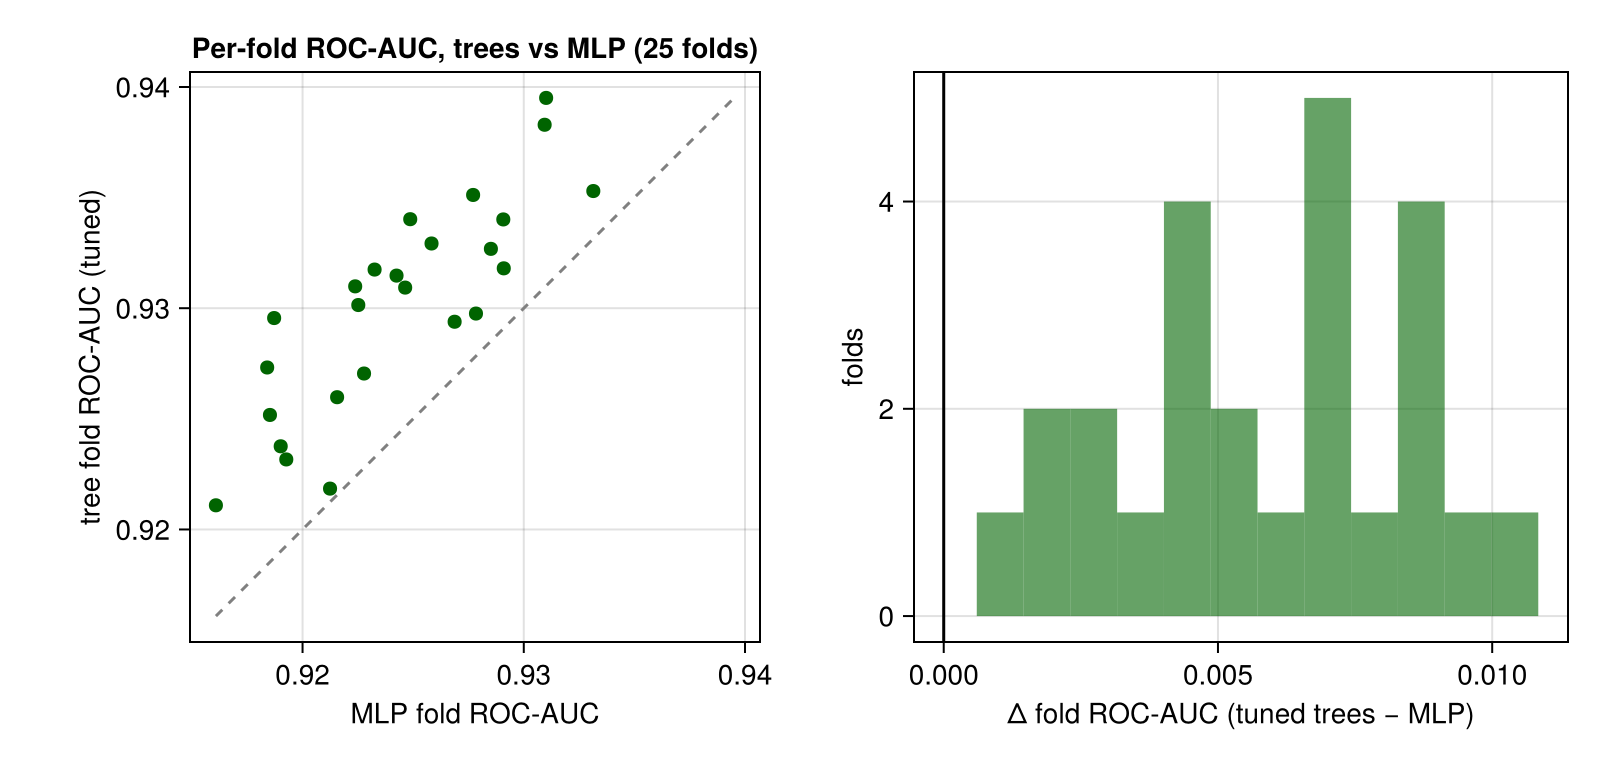

In [3]:
function fold_auc(cv)
    R, K = size(cv.folds, 2), maximum(cv.folds)
    [fast_auc(y[cv.folds[:, r] .== f], vec(mean(cv.oof[cv.folds[:, r] .== f, r, :]; dims = 2))) for r in 1:R for f in 1:K]
end
fa = Dict(name => fold_auc(cv) for (name, cv) in runs)
for name in ("Trees, untuned", "Trees, tuned", "Logistic regression")
    d = fa[name] .- fa["MLP (baseline)"]
    @printf("%-20s beats MLP on %2d/25 folds; per-fold Δ mean %+.4f, std %.4f, min %+.4f, max %+.4f\n",
            name, sum(d .> 0), mean(d), std(d), minimum(d), maximum(d))
end
fig = Figure(size = (800, 380))
ax = Axis(fig[1, 1]; xlabel = "MLP fold ROC-AUC", ylabel = "tree fold ROC-AUC (tuned)", aspect = 1,
          title = "Per-fold ROC-AUC, trees vs MLP (25 folds)")
scatter!(ax, fa["MLP (baseline)"], fa["Trees, tuned"]; color = :darkgreen, markersize = 10)
lo, hi = extrema([fa["MLP (baseline)"]; fa["Trees, tuned"]])
lines!(ax, [lo, hi], [lo, hi]; color = :gray, linestyle = :dash)
ax2 = Axis(fig[1, 2]; xlabel = "Δ fold ROC-AUC (tuned trees − MLP)", ylabel = "folds")
hist!(ax2, fa["Trees, tuned"] .- fa["MLP (baseline)"]; bins = 12, color = (:darkgreen, 0.6))
vlines!(ax2, [0]; color = :black)
savefig("exo101326_fold_pairs.png", fig)
fig

### 1.2 ROC and precision-recall curves (pooled OOF)

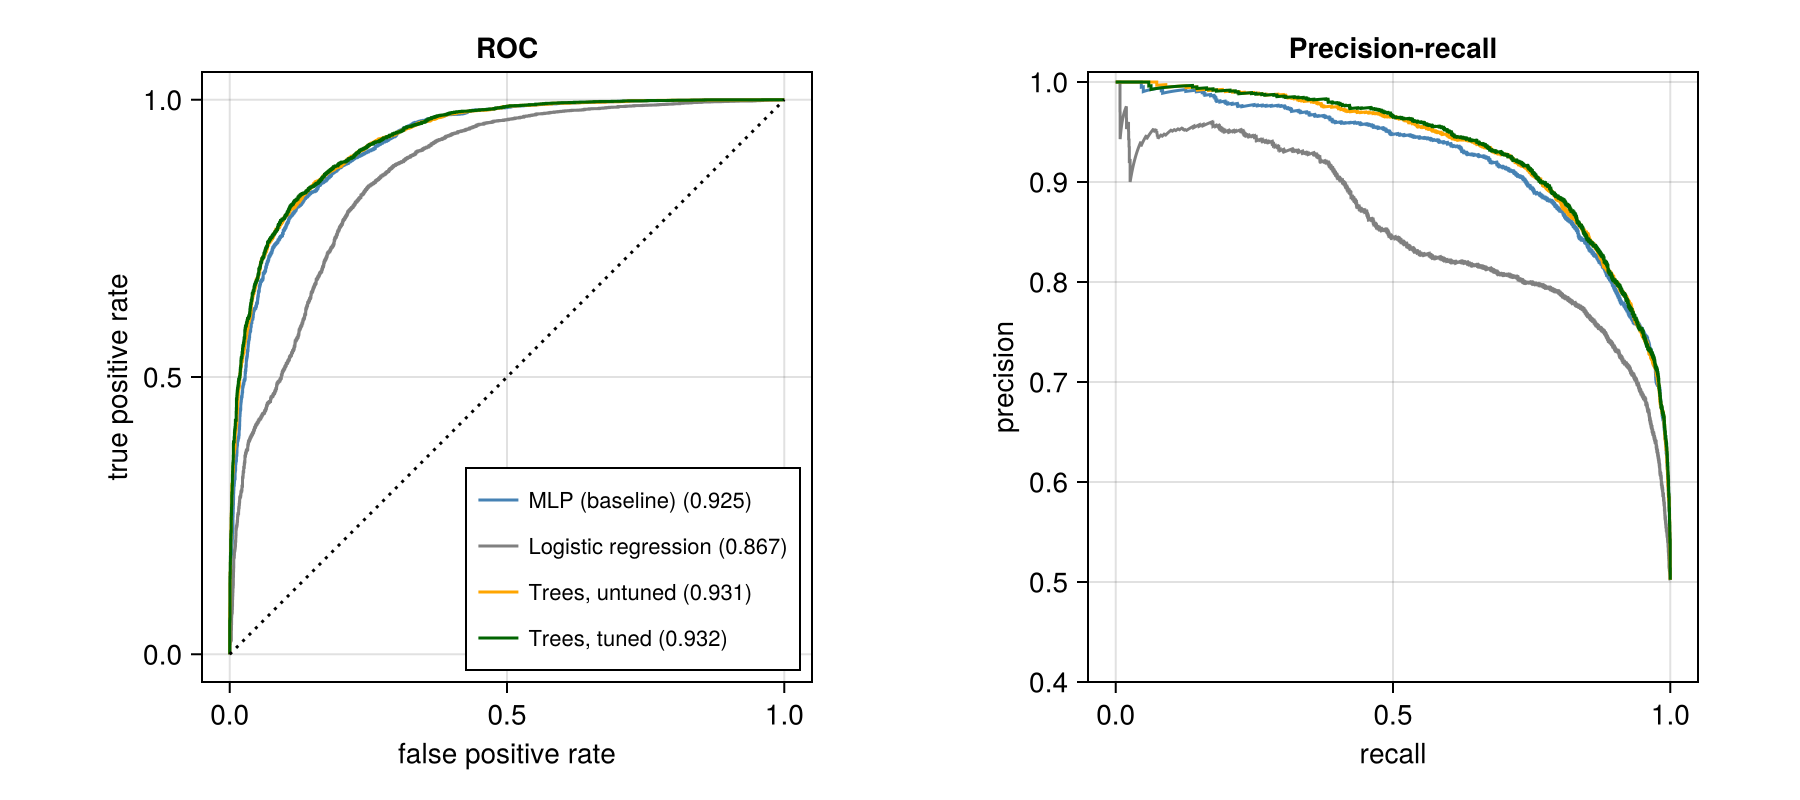

In [4]:
fig = Figure(size = (900, 400))
a1 = Axis(fig[1, 1]; xlabel = "false positive rate", ylabel = "true positive rate", title = "ROC", aspect = 1)
a2 = Axis(fig[1, 2]; xlabel = "recall", ylabel = "precision", title = "Precision-recall", aspect = 1)
for ((name, _), col) in zip(runs, (:steelblue, :gray, :orange, :darkgreen))
    s = scores[name]
    fpr, tpr = roccurve(Int.(y), s)
    rec, prec = prcurve(Int.(y), s)
    lines!(a1, fpr, tpr; color = col, label = @sprintf("%s (%.3f)", name, fast_auc(y, s)))
    lines!(a2, rec, prec; color = col)
end
lines!(a1, [0, 1], [0, 1]; color = :black, linestyle = :dot)
axislegend(a1; position = :rb, labelsize = 11)
ylims!(a2, 0.4, 1.01)
savefig("exo101326_roc_pr.png", fig)
fig

## 2. Tree tuning grid
60 settings (depth × min_weight × L2 × colsample; eta 0.05, rowsample 0.8, early stopping on the inner validation
split), each scored with 2 fold shuffles × 3 seeds on **separate** folds (`fold_seed0 = 5000`). The MLP on the same
tuning folds is the reference line.

MLP on tuning folds: AUC 0.9255;  best grid AUC 0.9318;  worst 0.9266;  untuned default (depth 5, mw 5, L2 1, cs 0.8) is not in the grid
8×7 DataFrame
 Row │ max_depth  min_weight  L2       colsample  roc_auc   logloss   median_rounds
     │ Int64      Float64     Float64  Float64    Float64   Float64   Float64
─────┼──────────────────────────────────────────────────────────────────────────────
   1 │         8        10.0     10.0        0.8  0.931842  0.331416          246.5
   2 │         8        10.0     10.0        0.5  0.931714  0.331845          283.0
   3 │         8         1.0     10.0        0.8  0.931694  0.332             230.0
   4 │         8         1.0     10.0        0.5  0.9316    0.3323            277.0
   5 │         8        40.0     10.0        0.8  0.931563  0.331999          274.5
   6 │         8         1.0      1.0        0.8  0.931259  0.333428          147.0
   7 │         8        40.0      1.0        0.8  0.931241  0.333036          179.5
   8 │        

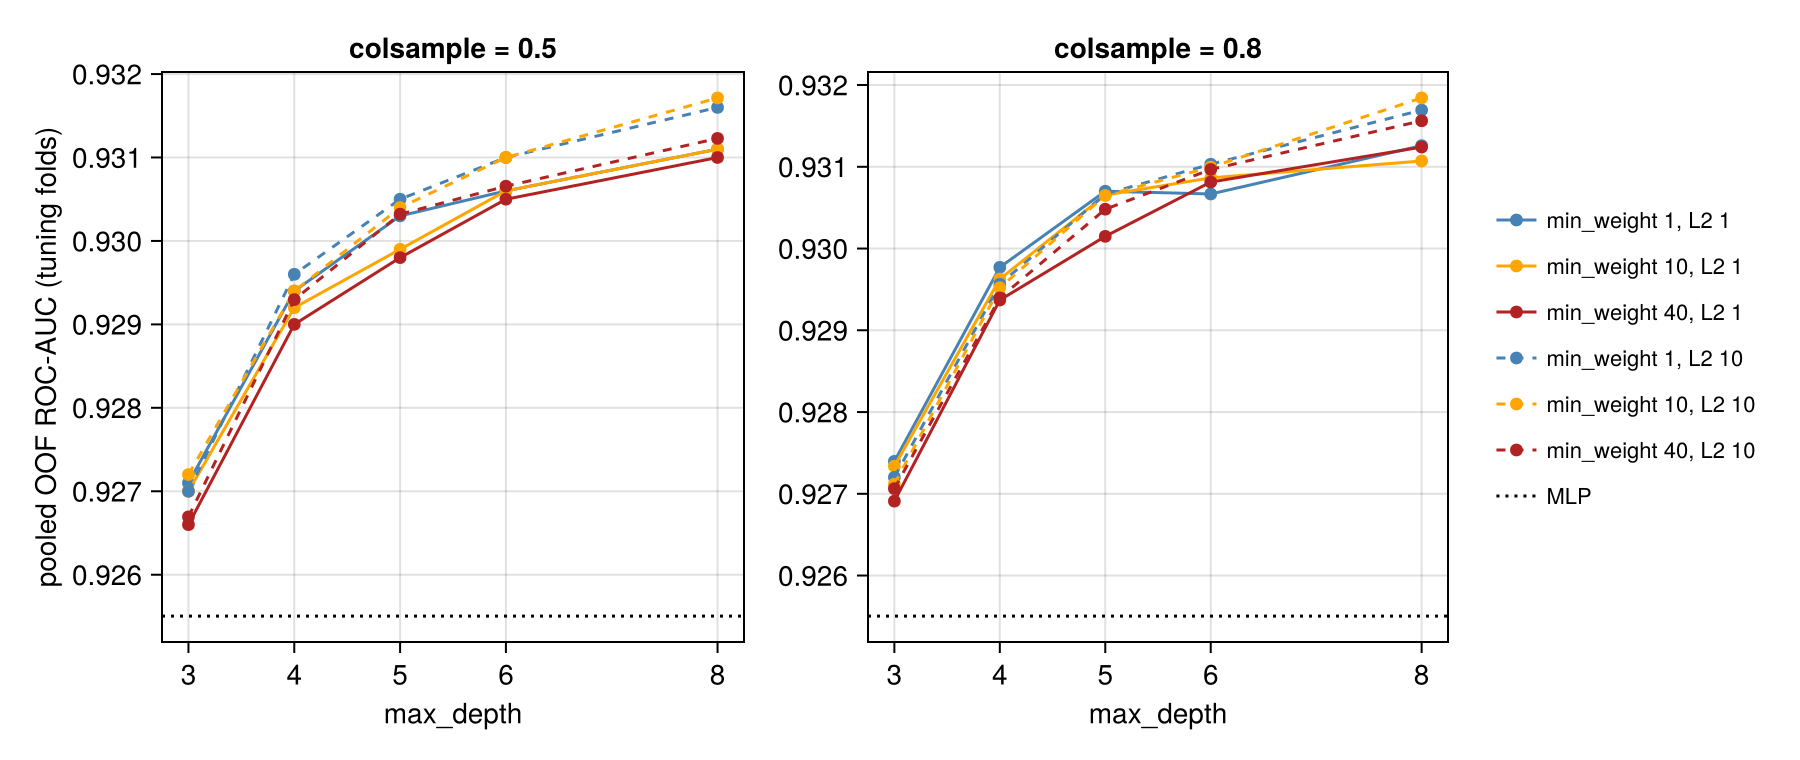

In [5]:
g = JLD2.load(joinpath(CV_DIR, "evotree_grid.jld2"))
gridres, mlp_ref = g["gridres"], g["mlp_ref_auc"]
@printf("MLP on tuning folds: AUC %.4f;  best grid AUC %.4f;  worst %.4f;  untuned default (depth 5, mw 5, L2 1, cs 0.8) is not in the grid\n",
        mlp_ref, maximum(gridres.roc_auc), minimum(gridres.roc_auc))
fig = Figure(size = (900, 380))
for (j, cs) in enumerate((0.5, 0.8))
    local ax = Axis(fig[1, j]; xlabel = "max_depth", ylabel = j == 1 ? "pooled OOF ROC-AUC (tuning folds)" : "",
              title = "colsample = $cs", xticks = [3, 4, 5, 6, 8])
    for (mw, l2, col, ls) in ((1.0, 1.0, :steelblue, :solid), (10.0, 1.0, :orange, :solid), (40.0, 1.0, :firebrick, :solid),
                              (1.0, 10.0, :steelblue, :dash), (10.0, 10.0, :orange, :dash), (40.0, 10.0, :firebrick, :dash))
        t = sort(gridres[(gridres.colsample .== cs) .& (gridres.min_weight .== mw) .& (gridres.L2 .== l2), :], :max_depth)
        scatterlines!(ax, t.max_depth, t.roc_auc; color = col, linestyle = ls, label = "min_weight $(Int(mw)), L2 $(Int(l2))")
    end
    hlines!(ax, [mlp_ref]; color = :black, linestyle = :dot, label = "MLP")
    j == 2 && Legend(fig[1, 3], ax; framevisible = false, labelsize = 11)
end
savefig("exo101326_tree_grid.png", fig)
println(first(gridres, 8))
fig

## 3. What the models rely on
One model of each kind fit on a single star-grouped 8/9–1/9 split of the pool (for illustration only; the scores above
come from the CV). LR coefficients are on z-scored inputs (log10 for period/depth/prad), so their size compares
directly. Tree importance is the share of total split gain.

In [6]:
tr, va = split_by_star(pool; at = (8 / 9,), seed = 7)
d1 = prepare_data(tr, va, va)
lrm, = train_model(d1; hidden = (), dropout = 0.0, lr = 1e-2, verbose = false)
tkw = Dict(Symbol(k) => v for (k, v) in runs[4][2].config["train_kw"])
tm, = train_evotree(d1; tkw...)
imp = leftjoin(logreg_coefs(lrm, d1.features), tree_importance(tm); on = :feature)
sort!(imp, :importance; rev = true)

Row,feature,coef,importance
,String,Float64,Float64?
1,koi_prad,-1.4192,0.255486
2,koi_period,-0.712878,0.152349
3,koi_duration,-0.709651,0.099418
4,koi_count,1.08625,0.0930584
5,koi_model_snr,-0.630743,0.082593
6,koi_impact,0.226955,0.0707036
7,koi_teq,-2.23559,0.0652416
8,koi_depth,0.570412,0.0637094
9,koi_steff,0.139302,0.0486821


## 4. Do the trees fix the step-2 blind spots?
Same groups as step 2 (threshold 0.5, ensemble OOF scores). Threshold-based rates depend on calibration as well as
ranking, so group AUCs (by detection source) are shown too.

In [7]:
a = with_vetting_info(pool, df_raw, scores["MLP (baseline)"])
a.tce_source = String.(coalesce.(a.koi_tce_delivname, "none (no TCE)"))
fp = a.label .== 0
groups = [("FP missed: SS only", fp .& (a.flag_pattern .== "SS")),
          ("FP missed: CO only", fp .& (a.flag_pattern .== "CO")),
          ("FP missed: NT only", fp .& (a.flag_pattern .== "NT")),
          ("FP missed: EC only", fp .& (a.flag_pattern .== "EC")),
          ("FP missed: koi_count ≥ 3", fp .& (a.koi_count .>= 3)),
          ("FP missed: koi_count = 1", fp .& (a.koi_count .== 1)),
          ("FP missed: all", fp),
          ("CONFIRMED called FP", a.koi_disposition .== "CONFIRMED"),
          ("CANDIDATE called FP", a.koi_disposition .== "CANDIDATE"),
          ("planet called FP: P < 1.5 d", (a.label .== 1) .& (a.koi_period .< 1.5)),
          ("planet called FP: all", a.label .== 1)]
err_rate(s, m, isfp) = isfp ? mean(s[m] .>= 0.5) : mean(s[m] .< 0.5)
blind = DataFrame(group = first.(groups), n = [sum(m) for (_, m) in groups])
for (name, _) in runs
    blind[!, name] = [round(100 * err_rate(scores[name], m, startswith(gname, "FP")); digits = 1) for (gname, m) in groups]
end
blind

Row,group,n,MLP (baseline),Logistic regression,"Trees, untuned","Trees, tuned"
,String,Int64,Float64,Float64,Float64,Float64
1,FP missed: SS only,1307,4.5,3.4,4.1,3.8
2,FP missed: CO only,464,37.9,42.2,38.8,37.5
3,FP missed: NT only,849,24.6,51.5,25.2,26.0
4,FP missed: EC only,111,23.4,41.4,22.5,22.5
5,FP missed: koi_count ≥ 3,43,79.1,93.0,76.7,79.1
6,FP missed: koi_count = 1,3860,14.2,23.3,15.0,14.6
7,FP missed: all,4125,16.1,25.9,16.9,16.6
8,CONFIRMED called FP,2473,4.8,10.3,3.5,3.6
9,CANDIDATE called FP,1690,31.1,22.1,28.8,29.8


In [8]:
src_tbl = combine(groupby(a, :tce_source), nrow => :n)
for (name, _) in runs
    s = scores[name]
    src_tbl[!, name * " AUC"] = [fast_auc(y[a.tce_source .== t], s[a.tce_source .== t]) for t in src_tbl.tce_source]
end
sort!(src_tbl, :n; rev = true)

Row,tce_source,n,MLP (baseline) AUC,Logistic regression AUC,"Trees, untuned AUC","Trees, tuned AUC"
,String,Int64,Float64,Float64,Float64,Float64
1,q1_q17_dr25_tce,7199,0.947545,0.900859,0.951892,0.952947
2,q1_q16_tce,570,0.55833,0.546111,0.585314,0.577222
3,q1_q17_dr24_tce,296,0.781322,0.766044,0.741236,0.746552
4,none (no TCE),223,0.740424,0.669403,0.75912,0.76197


## 5. How different are the MLP and the trees?
If they make different mistakes, averaging them should help. The 50/50 average uses the same folds and seeds, so it
goes through the same `compare_cv` test.

Spearman(MLP, trees) = 0.967;  different hard call on 6.5% of KOIs
MLP+trees average: AUC 0.9321;  vs MLP Δ +0.0070 [+0.0058, +0.0084] p_null 0.000;  vs trees Δ +0.0001 [-0.0011, +0.0013]


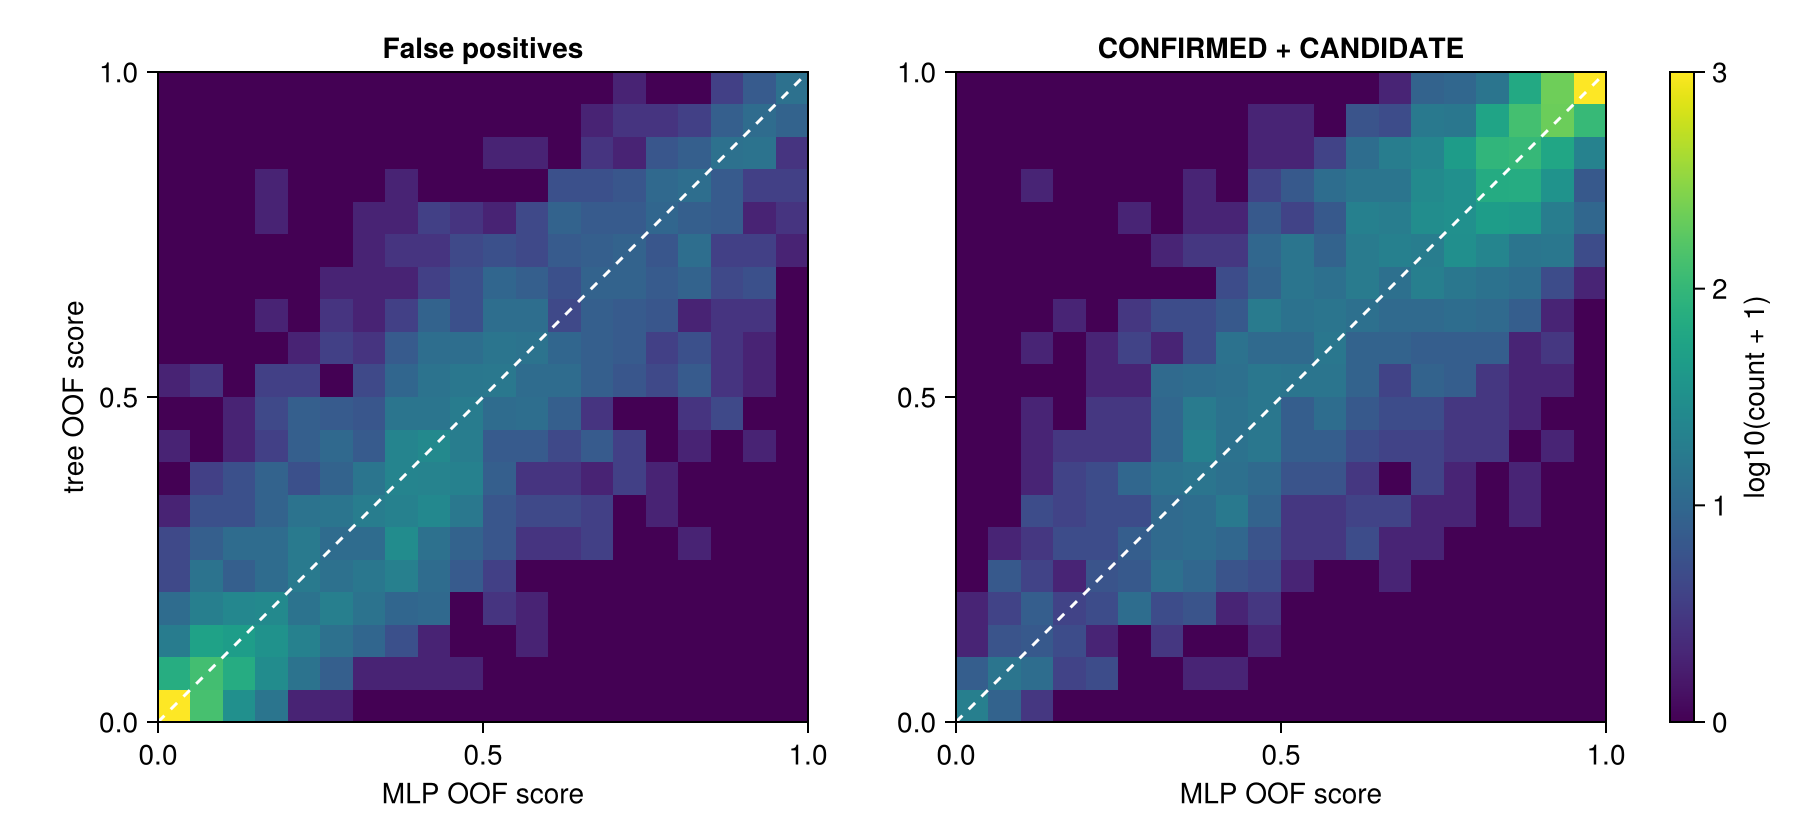

In [9]:
s_mlp, s_tree = scores["MLP (baseline)"], scores["Trees, tuned"]
tuned = runs[4][2]
avg = (oof = (base.oof .+ tuned.oof) ./ 2, folds = base.folds, kepoi = base.kepoi)
c_avg_mlp  = compare_cv(avg, base, pool; null = null_auc)
c_avg_tree = compare_cv(avg, tuned, pool)
@printf("Spearman(MLP, trees) = %.3f;  different hard call on %.1f%% of KOIs\n",
        corspearman(s_mlp, s_tree), 100 * mean((s_mlp .>= 0.5) .!= (s_tree .>= 0.5)))
@printf("MLP+trees average: AUC %.4f;  vs MLP Δ %+.4f [%+.4f, %+.4f] p_null %.3f;  vs trees Δ %+.4f [%+.4f, %+.4f]\n",
        c_avg_mlp.A, c_avg_mlp.delta, c_avg_mlp.ci_lo, c_avg_mlp.ci_hi, c_avg_mlp.p_null,
        c_avg_tree.delta, c_avg_tree.ci_lo, c_avg_tree.ci_hi)
fig = Figure(size = (900, 420))
for (j, (lab, ttl)) in enumerate(((0, "False positives"), (1, "CONFIRMED + CANDIDATE")))
    m = y .== lab
    local ax = Axis(fig[1, j]; xlabel = "MLP OOF score", ylabel = j == 1 ? "tree OOF score" : "", title = ttl, aspect = 1)
    h = fit(Histogram, (s_mlp[m], s_tree[m]), (0:0.05:1.0001, 0:0.05:1.0001))
    heatmap!(ax, 0.025:0.05:1, 0.025:0.05:1, log10.(h.weights .+ 1); colormap = :viridis)
    lines!(ax, [0, 1], [0, 1]; color = :white, linestyle = :dash)
    limits!(ax, 0, 1, 0, 1)
end
Colorbar(fig[1, 3]; colormap = :viridis, label = "log10(count + 1)", limits = (0, 3))
savefig("exo101326_mlp_vs_trees.png", fig)
fig

### 5.1 Calibration at a glance
Fraction of planets in 10 score bins (pooled OOF). Full calibration and threshold choice are step 5; this only checks
whether the threshold-0.5 rates in section 4 compare like with like.

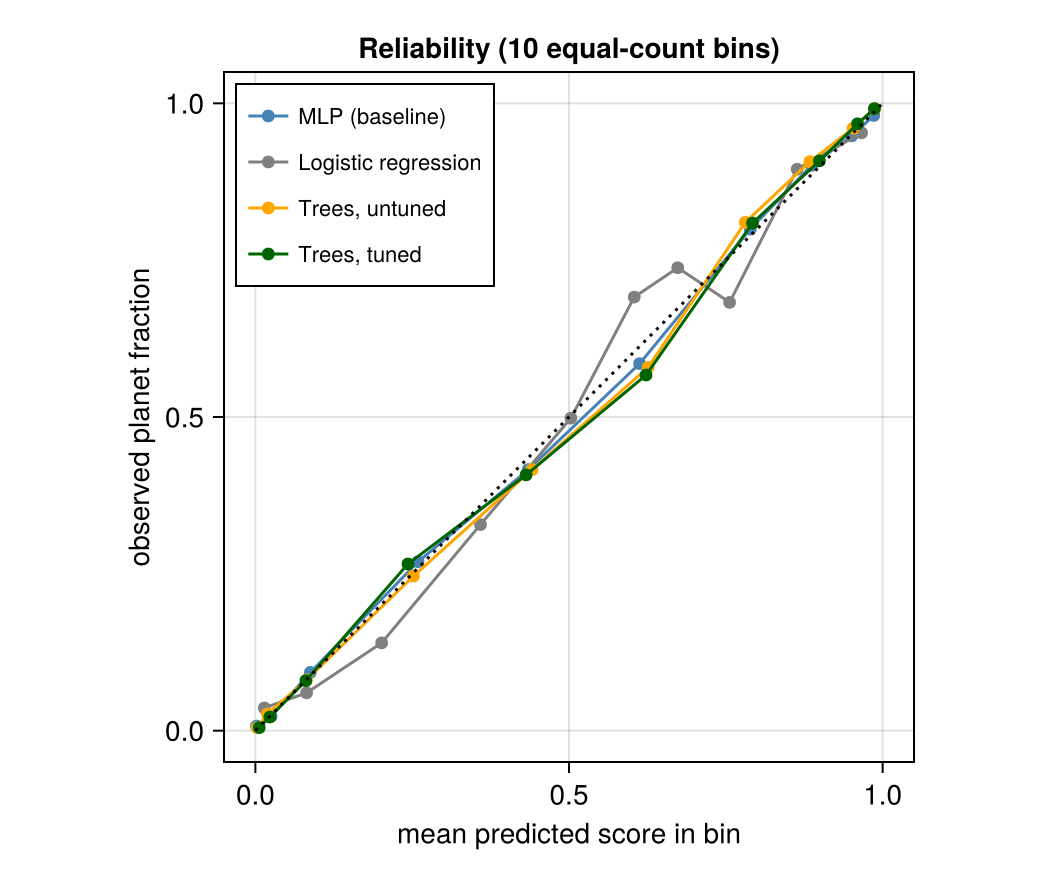

In [10]:
fig = Figure(size = (520, 440))
ax = Axis(fig[1, 1]; xlabel = "mean predicted score in bin", ylabel = "observed planet fraction", aspect = 1,
          title = "Reliability (10 equal-count bins)")
for ((name, _), col) in zip(runs, (:steelblue, :gray, :orange, :darkgreen))
    s = scores[name]
    edges = quantile(s, range(0, 1; length = 11))
    b = clamp.(searchsortedlast.(Ref(edges), s), 1, 10)
    scatterlines!(ax, [mean(s[b .== i]) for i in 1:10], [mean(y[b .== i]) for i in 1:10]; color = col, label = name)
end
lines!(ax, [0, 1], [0, 1]; color = :black, linestyle = :dot)
axislegend(ax; position = :lt, labelsize = 11)
savefig("exo101326_reliability.png", fig)
fig

In [11]:
oof_out = DataFrame(kepoi_name = pool.kepoi_name, kepid = pool.kepid, koi_disposition = pool.koi_disposition,
                    label = y, mlp = s_mlp, logreg = scores["Logistic regression"],
                    tree_default = scores["Trees, untuned"], tree_tuned = s_tree)
CSV.write(joinpath(CV_DIR, "oof_baselines_r5s10.csv"), oof_out)
println("wrote sweeps/results/oof_baselines_r5s10.csv  ($(nrow(oof_out)) rows)");

wrote sweeps/results/oof_baselines_r5s10.csv  (8288 rows)


## 6. Conclusions
1. **Trees are the stronger tabular model:** +0.007 ROC-AUC and −0.015 log-loss vs the MLP, consistent on every fold,
   and just as well calibrated (section 5.1). The step-1 bar (0.0005) is cleared by more than 10×.
2. **The gap is modest compared with the sampling uncertainty** of the pool itself (±0.006) and the sealed test set
   (±0.009): on the test split alone, the two models would be hard to tell apart.
3. **Same blind spots for every model.** Centroid offsets, not-transit-like signals, contamination, multi-KOI FPs and
   supplemental KOIs are missed at the same rates by LR, MLP and trees. This points to missing *information*, which
   is what step 4 (features, supplemental-KOI scoping) and Phase 2 (light curves, centroids) address.
4. **Caveat:** the trees were tuned on different fold shuffles of the same pool, so the tuned number is very slightly
   optimistic. The untuned trees (no tuning at all) already beat the MLP by +0.0056.

**Decisions for the next session (not done here):**
- Which model to carry forward as the tabular reference for steps 4–5: trees, the MLP, or both?
  - Trees are cheaper (~0.3 s per model vs ~2 s) and better.
  - The MLP is the project's stated model and the natural base for the Phase-2 hybrid (catalog features + light-curve CNN).
- Whether to try closing the MLP gap first (e.g. wider layers, more epochs, since some runs hit the 200-epoch cap;
  see step 1), or go straight to step 4 features, which should help both.
- Optional: extend the tree grid to depth 10–12 (≈ 5 min).

**Follow-up (same day, section 7):** we carry both models forward and tried to close the MLP gap by tuning. The best
MLP (learning rate 3e-3, 600-epoch cap) gains a real +0.0014 but is still 0.0055 behind the trees.

Files: `sweeps/cv_baselines.jl`, `sweeps/cv_mlp_gap.jl` (compute), `sweeps/results/cv_logreg_r5s10.jld2`, `cv_evotree_default_r5s10.jld2`,
`cv_evotree_tuned_r5s10.jld2`, `evotree_grid.csv/.jld2`, `oof_baselines_r5s10.csv` (per-KOI scores of all models),
`src/Baselines.jl`, figures `figures/exo101326_*.png`.

## 7. Follow-up: can tuning close the MLP gap?
Decision: carry **both** models forward, and first try to close the MLP's gap by tuning (`sweeps/cv_mlp_gap.jl`).

**Screen:** 11 single changes plus 3 combinations, on the same tuning folds as the tree grid (2 fold shuffles × 3
seeds). Δ is paired against the unchanged MLP on those folds (0.9255); the best tree there scored 0.9318.
AdamW weight decay is lr-coupled (decay per step = lr × wd).

In [12]:
screen = CSV.read(joinpath(CV_DIR, "mlp_screen.csv"), DataFrame)
select(screen, :variant, :roc_auc, :d_auc, :ci_lo, :ci_hi, :logloss, :median_epoch)

Row,variant,roc_auc,d_auc,ci_lo,ci_hi,logloss,median_epoch
,DataStri…,Float64,Float64,Float64,Float64,Float64,Float64
1,lr3_e600_quantile,0.932128,0.00662366,0.00412822,0.00933825,0.330371,40.5
2,lr3_e600_logmore,0.931393,0.00588905,0.00376688,0.00814456,0.331734,37.5
3,lr3e-3,0.926391,0.00088689,0.000166599,0.0015774,0.34356,56.5
4,epochs600,0.92626,0.000755516,0.000349698,0.00117275,0.344011,115.5
5,wide256,0.926158,0.000654074,-0.000163973,0.00142465,0.344734,49.0
6,deep3,0.926084,0.000579885,-0.000312309,0.0013927,0.344443,46.5
7,drop0.1,0.925685,0.000180843,-0.000304693,0.000676857,0.345262,84.0
8,base,0.925504,0.0,0.0,0.0,0.345562,99.0
9,wide128,0.925456,-4.78676e-5,-0.000706328,0.000591437,0.345935,62.5


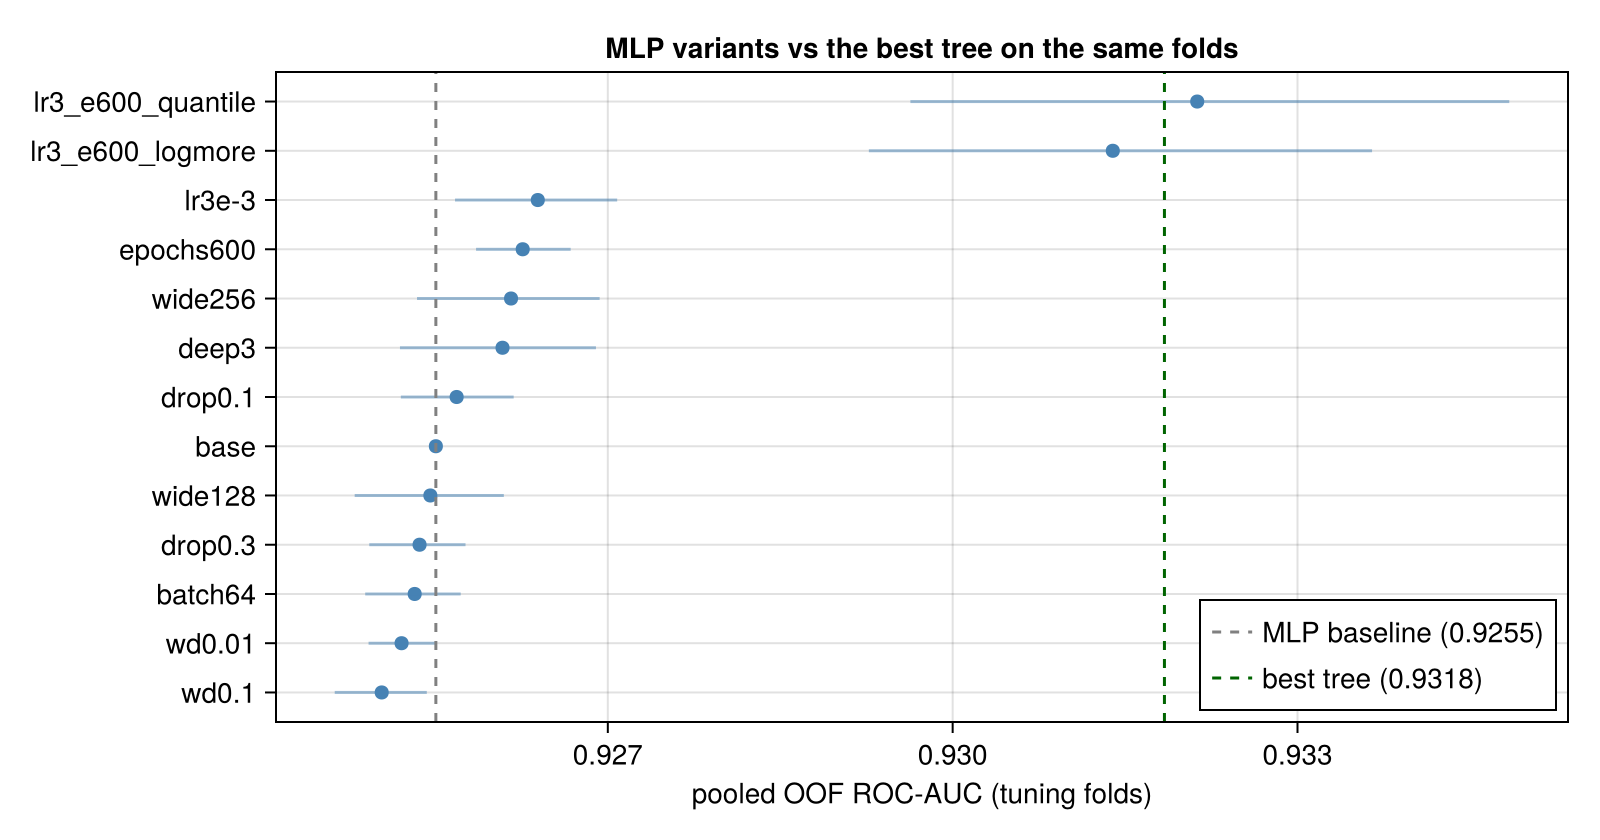

In [13]:
fig = Figure(size = (800, 420))
ax = Axis(fig[1, 1]; xlabel = "pooled OOF ROC-AUC (tuning folds)", yticks = (1:nrow(screen), reverse(screen.variant)),
          title = "MLP variants vs the best tree on the same folds")
order = nrow(screen):-1:1
scatter!(ax, screen.roc_auc, order; color = :steelblue, markersize = 10)
rangebars!(ax, order, screen.roc_auc .- screen.d_auc .+ screen.ci_lo, screen.roc_auc .- screen.d_auc .+ screen.ci_hi;
           direction = :x, color = (:steelblue, 0.5))
vlines!(ax, [screen.roc_auc[screen.variant .== "base"][1]]; color = :gray, linestyle = :dash, label = "MLP baseline (0.9255)")
vlines!(ax, [maximum(gridres.roc_auc)]; color = :darkgreen, linestyle = :dash, label = @sprintf("best tree (%.4f)", maximum(gridres.roc_auc)))
axislegend(ax; position = :rb)
savefig("exo101326_mlp_screen.png", fig)
fig

Bars: paired 95% star-bootstrap CI of each variant's gain over the baseline, drawn around the variant's AUC.

**Final check on the standard folds** (5 shuffles × 10 seeds, the step-1 protocol) for the best variant, `lr3_e600`
(learning rate 3e-3, epoch cap 600, patience 50):

In [14]:
mlp2 = load_cv("cv_mlp_lr3_e600_r5s10.jld2")
@assert mlp2.folds == base.folds
c_b = compare_cv(mlp2, base, pool; null = null_auc)
c_t = compare_cv(mlp2, tuned, pool)
c_l = compare_cv(mlp2, base, pool; null = null_ll, metric = logloss)
@printf("tuned MLP: AUC %.4f, log-loss %.4f\n", c_b.A, c_l.A)
@printf("  vs baseline MLP: Δ AUC %+.4f [%+.4f, %+.4f], p_null %.3f;  Δ log-loss %+.4f [%+.4f, %+.4f]\n",
        c_b.delta, c_b.ci_lo, c_b.ci_hi, c_b.p_null, c_l.delta, c_l.ci_lo, c_l.ci_hi)
@printf("  vs tuned trees:   Δ AUC %+.4f [%+.4f, %+.4f]  (gap closed: %.0f%%)\n",
        c_t.delta, c_t.ci_lo, c_t.ci_hi, 100 * c_b.delta / (c_b.delta - c_t.delta))
@printf("  median best epoch %.0f (baseline %.0f); runs stopping within patience of the cap: %.1f%%\n",
        median(mlp2.results.best_epoch), median(base.results.best_epoch), 100 * mean(mlp2.results.best_epoch .>= 550))

tuned MLP: AUC 0.9265, log-loss 0.3432
  vs baseline MLP: Δ AUC +0.0014 [+0.0009, +0.0019], p_null 0.000;  Δ log-loss -0.0031 [-0.0042, -0.0020]
  vs tuned trees:   Δ AUC -0.0055 [-0.0080, -0.0032]  (gap closed: 20%)
  median best epoch 59 (baseline 96); runs stopping within patience of the cap: 0.0%


**Reading this:**
- **Real but small gains.** A higher learning rate and a 600-epoch cap help, and the gain clears both step-1 checks.
  Neither change alone, nor more capacity (wider or 3 layers), nor dropout, weight decay or batch size moves the MLP
  more than ~0.001.
- **The tuned MLP closes only about a fifth of the gap** to the trees.
- **The gap is not about training or capacity.** The most likely cause is the **input representation**:
  - Trees only see the order of each feature's values, so skewed, heavy-tailed inputs don't bother them.
  - The MLP sees z-scored raw values, and only period, depth and prad are logged.
  - SNR, duration, teq, srad and koi_count are strongly skewed and are not logged.
  - Testing that (log SNR etc., or a quantile transform) is a feature-preprocessing change, which belongs in step 4.

## 8. Step 4, part 1: input transforms for the MLP
Decision: adopt the tuned MLP (`lr3_e600`) as the new MLP reference, and test the input-representation explanation.
As the MLP saw them, several features were extremely skewed: impact (skew 23; values up to 100 against a typical
0–1.3), stellar radius (22), duration (6), SNR (5), teq (4); some inputs sat 38σ from the mean. Two fixes, both
fit on the training part only (`prepare_data(...; transform)`):
- **`log_more`:** log10 also on duration, SNR (+1), teq, srad, koi_count and impact (+0.1).
- **`quantile`** (rank-gauss): each feature → its empirical CDF on the training part → standard-normal quantile.
  Immune to outliers; max |z| drops from 38 to 4.5.

Trees are unaffected by either (they only use the order of values). Same standard folds, 5 shuffles × 10 seeds.

In [15]:
runs4 = [("MLP baseline (exo100926)", base),
         ("MLP tuned (lr3_e600)", mlp2),
         ("MLP tuned + log_more", load_cv("cv_mlp_lr3_e600_logmore_r5s10.jld2")),
         ("MLP tuned + quantile", load_cv("cv_mlp_lr3_e600_quantile_r5s10.jld2")),
         ("Trees, tuned", tuned)]
for (_, cv) in runs4; @assert cv.folds == base.folds; end
mq = runs4[4][2]
rows4 = map(runs4) do (name, cv)
    cb = compare_cv(cv, base, pool; null = null_auc)
    cm = compare_cv(cv, mlp2, pool)
    ct = compare_cv(cv, tuned, pool)
    s = oof_scores(cv)
    conf = pool.koi_disposition .!= "CANDIDATE"
    (model = name, roc_auc = cb.A, logloss = logloss(y, s), roc_auc_conf = fast_auc(y[conf], s[conf]),
     vs_baseline = @sprintf("%+.4f [%+.4f, %+.4f]", cb.delta, cb.ci_lo, cb.ci_hi),
     vs_tuned_mlp = @sprintf("%+.4f [%+.4f, %+.4f]", cm.delta, cm.ci_lo, cm.ci_hi),
     vs_trees = @sprintf("%+.4f [%+.4f, %+.4f]", ct.delta, ct.ci_lo, ct.ci_hi))
end
DataFrame(rows4)

Row,model,roc_auc,logloss,roc_auc_conf,vs_baseline,vs_tuned_mlp,vs_trees
,String,Float64,Float64,Float64,String,String,String
1,MLP baseline (exo100926),0.925054,0.346302,0.96376,"+0.0000 [+0.0000, +0.0000]","-0.0014 [-0.0019, -0.0009]","-0.0069 [-0.0094, -0.0045]"
2,MLP tuned (lr3_e600),0.926472,0.343197,0.965005,"+0.0014 [+0.0009, +0.0019]","+0.0000 [+0.0000, +0.0000]","-0.0055 [-0.0080, -0.0032]"
3,MLP tuned + log_more,0.932633,0.32944,0.973616,"+0.0076 [+0.0055, +0.0100]","+0.0062 [+0.0042, +0.0084]","+0.0006 [-0.0015, +0.0028]"
4,MLP tuned + quantile,0.933017,0.328393,0.974231,"+0.0080 [+0.0056, +0.0106]","+0.0065 [+0.0042, +0.0092]","+0.0010 [-0.0012, +0.0031]"
5,"Trees, tuned",0.932002,0.331245,0.972962,"+0.0069 [+0.0045, +0.0094]","+0.0055 [+0.0032, +0.0080]","+0.0000 [+0.0000, +0.0000]"


### 8.1 Blind spots and detection sources with the transformed MLP
Same groups as section 4 (% wrong at threshold 0.5), plus ROC-AUC by TCE source.

In [16]:
s_q = oof_scores(mq)
blind4 = select(blind, :group, :n, "MLP (baseline)", "Trees, tuned")
blind4[!, "MLP + quantile"] = [round(100 * err_rate(s_q, m, startswith(g, "FP")); digits = 1) for (g, m) in groups]
src4 = select(src_tbl, :tce_source, :n, "MLP (baseline) AUC", "Trees, tuned AUC")
src4[!, "MLP + quantile AUC"] = [fast_auc(y[a.tce_source .== t], s_q[a.tce_source .== t]) for t in src4.tce_source]
println(src4)
blind4

4×5 DataFrame
 Row │ tce_source       n      MLP (baseline) AUC  Trees, tuned AUC  MLP + quantile AUC
     │ String           Int64  Float64             Float64           Float64
─────┼──────────────────────────────────────────────────────────────────────────────────
   1 │ q1_q17_dr25_tce   7199            0.947545          0.952947            0.953124
   2 │ q1_q16_tce         570            0.55833           0.577222            0.577222
   3 │ q1_q17_dr24_tce    296            0.781322          0.746552            0.779646
   4 │ none (no TCE)      223            0.740424          0.76197             0.767898


Row,group,n,MLP (baseline),"Trees, tuned",MLP + quantile
,String,Int64,Float64,Float64,Float64
1,FP missed: SS only,1307,4.5,3.8,4.1
2,FP missed: CO only,464,37.9,37.5,35.1
3,FP missed: NT only,849,24.6,26.0,20.4
4,FP missed: EC only,111,23.4,22.5,22.5
5,FP missed: koi_count ≥ 3,43,79.1,79.1,74.4
6,FP missed: koi_count = 1,3860,14.2,14.6,12.3
7,FP missed: all,4125,16.1,16.6,14.3
8,CONFIRMED called FP,2473,4.8,3.6,4.0
9,CANDIDATE called FP,1690,31.1,29.8,33.1


### 8.2 Now that they are equally good: do the MLP and the trees combine?

Spearman(quantile MLP, trees) = 0.976;  different hard call on 5.9% of KOIs
50/50 average: AUC 0.9352, log-loss 0.3239;  vs quantile MLP Δ +0.0022 [+0.0011, +0.0032];  vs trees Δ +0.0032 [+0.0021, +0.0043]


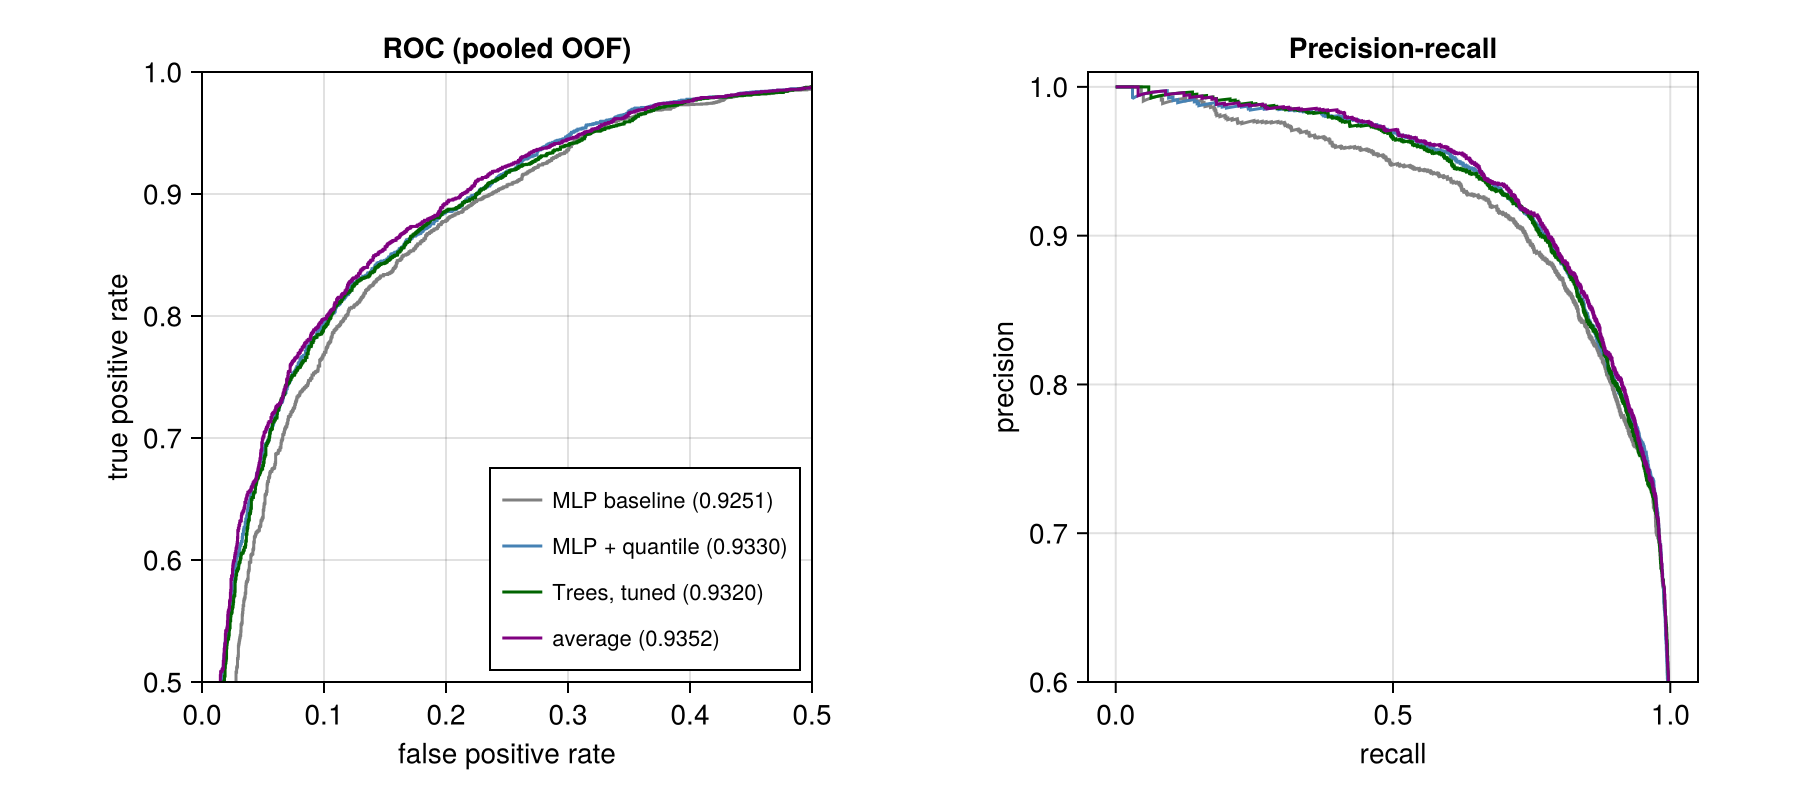

In [17]:
avg4 = (oof = (mq.oof .+ tuned.oof) ./ 2, folds = base.folds, kepoi = base.kepoi)
c4_q = compare_cv(avg4, mq, pool)
c4_t = compare_cv(avg4, tuned, pool)
@printf("Spearman(quantile MLP, trees) = %.3f;  different hard call on %.1f%% of KOIs\n",
        corspearman(s_q, s_tree), 100 * mean((s_q .>= 0.5) .!= (s_tree .>= 0.5)))
@printf("50/50 average: AUC %.4f, log-loss %.4f;  vs quantile MLP Δ %+.4f [%+.4f, %+.4f];  vs trees Δ %+.4f [%+.4f, %+.4f]\n",
        c4_q.A, logloss(y, oof_scores(avg4)), c4_q.delta, c4_q.ci_lo, c4_q.ci_hi, c4_t.delta, c4_t.ci_lo, c4_t.ci_hi)
fig = Figure(size = (900, 400))
a1 = Axis(fig[1, 1]; xlabel = "false positive rate", ylabel = "true positive rate", title = "ROC (pooled OOF)", aspect = 1)
a2 = Axis(fig[1, 2]; xlabel = "recall", ylabel = "precision", title = "Precision-recall", aspect = 1)
for ((name, sc), col) in zip((("MLP baseline", s_mlp), ("MLP + quantile", s_q), ("Trees, tuned", s_tree),
                              ("average", oof_scores(avg4))), (:gray, :steelblue, :darkgreen, :purple))
    fpr, tpr = roccurve(Int.(y), sc); rec, prec = prcurve(Int.(y), sc)
    lines!(a1, fpr, tpr; color = col, label = @sprintf("%s (%.4f)", name, fast_auc(y, sc)))
    lines!(a2, rec, prec; color = col)
end
axislegend(a1; position = :rb, labelsize = 11)
xlims!(a1, 0, 0.5); ylims!(a1, 0.5, 1.0); ylims!(a2, 0.6, 1.01)
savefig("exo101326_transforms_roc.png", fig)
fig

**Reading section 8:**
- **The input representation was the whole gap.**
  - The quantile-transformed MLP reaches **0.9330**: +0.008 over the original MLP, +0.0065 over the tuned MLP.
  - That's **level with the tuned trees** (Δ +0.0010, CI includes 0).
  - `log_more` gets almost as far (0.9326). The rest of the tuning (width, depth, dropout…) never mattered.
- **Blind spots shrink a little but remain** (threshold 0.5):

  | Group | MLP baseline | Quantile MLP |
  |---|---|---|
  | Missed FPs overall | 16.1% | 14.3% |
  | NT-only FPs missed | 24.6% | 20.4% |
  | CO-only FPs missed | 37.9% | 35.1% |
  | FPs with 3+ KOIs missed | 79% | 74% |
  | Q1–Q16-only KOIs, AUC | 0.56 | 0.58 |

  CANDIDATEs called FP rise slightly (31% → 33%), partly a threshold shift. Centroid offsets and supplemental KOIs
  are still the limit: an information problem, not a model problem.
- **Now the two models do combine.** The quantile MLP and the trees agree slightly more than before (Spearman 0.976),
  yet the 50/50 average reaches **0.9352**:
  - +0.0022 [+0.0011, +0.0032] over the quantile MLP;
  - +0.0032 [+0.0021, +0.0043] over the trees;
  - log-loss 0.324, the best so far.

  With the original MLP, averaging added nothing. Once both models are equally good, their remaining errors are partly independent.
- **Recommendation for the rest of step 4:**
  - MLP reference: `transform = :quantile` + `lr3_e600`.
  - Keep the trees.
  - Report the MLP + trees average as the combined model.

## 9. Step 4, part 2: `koi_count` ablation, `koi_insol`, deeper trees
Compute: `sweeps/step4_features.jl`. References: quantile MLP, tuned trees, and their average (section 8).

**`koi_insol` (not run, on purpose):** on the pool, Spearman(`koi_insol`, `koi_teq`) = **1.0000**, because teq is computed
from insolation. Trees only use the order of values, and the quantile transform maps both to identical inputs, so
`koi_insol` adds exactly zero information to either reference model. It stays out.

**`koi_count` ablation:** how much of the performance is the multiplicity prior ("a star with several KOIs is
probably a planetary system")? Both models retrained on the 10 other features, same folds.

In [18]:
mq_nc = load_cv("cv_mlpq_nocount_r5s10.jld2")
tr_nc = load_cv("cv_evotree_nocount_r5s10.jld2")
avg_nc = (oof = (mq_nc.oof .+ tr_nc.oof) ./ 2, folds = base.folds, kepoi = base.kepoi)
abl = map([("MLP + quantile", mq, mq_nc), ("Trees, tuned", tuned, tr_nc), ("MLP + trees average", avg4, avg_nc)]) do (name, with, without)
    c = compare_cv(without, with, pool)
    cl = compare_cv(without, with, pool; metric = logloss)
    (model = name, with_count = c.B, without_count = c.A, d_auc = @sprintf("%+.4f [%+.4f, %+.4f]", c.delta, c.ci_lo, c.ci_hi),
     d_logloss = @sprintf("%+.4f [%+.4f, %+.4f]", cl.delta, cl.ci_lo, cl.ci_hi))
end
DataFrame(abl)

Row,model,with_count,without_count,d_auc,d_logloss
,String,Float64,Float64,String,String
1,MLP + quantile,0.933017,0.929396,"-0.0036 [-0.0053, -0.0019]","+0.0087 [+0.0047, +0.0126]"
2,"Trees, tuned",0.932002,0.928036,"-0.0040 [-0.0057, -0.0022]","+0.0101 [+0.0063, +0.0138]"
3,MLP + trees average,0.935175,0.931456,"-0.0037 [-0.0053, -0.0021]","+0.0094 [+0.0057, +0.0128]"


Where does the loss come from? Error rates (threshold 0.5) for the average model, with and without `koi_count`,
split by multiplicity:

In [19]:
s_av, s_av_nc = oof_scores(avg4), oof_scores(avg_nc)
mult_groups = [("FP missed: koi_count = 1", fp .& (a.koi_count .== 1)),
               ("FP missed: koi_count = 2", fp .& (a.koi_count .== 2)),
               ("FP missed: koi_count ≥ 3", fp .& (a.koi_count .>= 3)),
               ("planet called FP: koi_count = 1", (y .== 1) .& (a.koi_count .== 1)),
               ("planet called FP: koi_count = 2", (y .== 1) .& (a.koi_count .== 2)),
               ("planet called FP: koi_count ≥ 3", (y .== 1) .& (a.koi_count .>= 3))]
DataFrame(group = first.(mult_groups), n = [sum(m) for (_, m) in mult_groups],
          with_count = [round(100 * err_rate(s_av, m, startswith(g, "FP")); digits = 1) for (g, m) in mult_groups],
          without_count = [round(100 * err_rate(s_av_nc, m, startswith(g, "FP")); digits = 1) for (g, m) in mult_groups])

Row,group,n,with_count,without_count
,String,Int64,Float64,Float64
1,FP missed: koi_count = 1,3860,13.1,14.6
2,FP missed: koi_count = 2,222,36.5,26.6
3,FP missed: koi_count ≥ 3,43,76.7,51.2
4,planet called FP: koi_count = 1,2428,23.3,21.0
5,planet called FP: koi_count = 2,920,2.9,6.2
6,planet called FP: koi_count ≥ 3,815,1.2,3.8


In [20]:
multi_auc = DataFrame(koi_count = String[], n = Int[], planet_frac = Float64[], auc_with = Float64[], auc_without = Float64[])
for (lab, m) in (("1", a.koi_count .== 1), ("2", a.koi_count .== 2), ("≥ 3", a.koi_count .>= 3))
    push!(multi_auc, (lab, sum(m), mean(y[m]), fast_auc(y[m], s_av[m]), fast_auc(y[m], s_av_nc[m])))
end
multi_auc

Row,koi_count,n,planet_frac,auc_with,auc_without
,String,Int64,Float64,Float64,Float64
1,1,6288,0.386132,0.912423,0.912367
2,2,1142,0.805604,0.921411,0.923296
3,≥ 3,858,0.949883,0.908375,0.907119


**Deeper trees:** depth 8 was the edge of the step-3 grid. Screened on the same tuning folds (min_weight 10, L2 10,
colsample 0.8):

In [21]:
CSV.read(joinpath(CV_DIR, "evotree_depth_screen.csv"), DataFrame)

Row,max_depth,roc_auc,logloss,median_rounds
,Int64,Float64,Float64,Float64
1,8,0.931842,NaN,NaN
2,10,0.931931,0.331223,193.5
3,12,0.932125,0.330887,177.5


**Reading section 9:**
- **`koi_count` is worth ~0.004 ROC-AUC to every model** (MLP −0.0036, trees −0.0040, average −0.0037; all CIs
  exclude 0; log-loss worsens by ~0.009).
- **It is a pure prior: it works between groups, not within them.**
  - Within each multiplicity group, ranking quality is unchanged without it (AUC 0.912 vs 0.912 for single-KOI stars,
    0.921 vs 0.923 for 2, 0.908 vs 0.907 for 3+).
  - All it does is shift scores by group: multi-KOI systems are 81% (2 KOIs) and 95% (3+) planets, singles only 39%.
  - This matches the known multiplicity boost (false positives rarely come in multiples), and is a legitimate prior,
    not leakage.
- **The trade-off is visible at threshold 0.5** (average model, with → without `koi_count`):

  | Group | With | Without |
  |---|---|---|
  | FPs missed, 3+ KOI systems | 77% | 51% |
  | FPs missed, 2-KOI systems | 37% | 27% |
  | Planets called FP, 2-KOI systems | 2.9% | 6.2% |
  | Planets called FP, 3+ KOI systems | 1.2% | 3.8% |

  Since multi-KOI systems are mostly planets, the net effect is worse.
- **Recommendation: keep `koi_count`.** Remember that the model "trusts" multis by design: a false positive on a
  multi-planet star is the hardest case for the catalog-only model, and an obvious target for Phase 2.
- **`koi_insol`: stays out** (a rank copy of teq; zero new information).
- **Deeper trees: no gain.** Depth 10: +0.0001, depth 12: +0.0003 over depth 8 on the tuning folds, below the 0.0005
  bar. Depth 8 stays.

## 10. Step 4, part 3: centroid features and supplemental-KOI scoping
**Decisions (10/13), from the recommendations:**
1. **Centroid features are allowed, as a separate model.**
   - The "catalog + centroid" model sits next to the catalog-only reference; both are reported.
   - The 7 features (`src/Centroids.jl`): difference-image offsets from the out-of-transit centroid and from the
     KIC position, in arcsec and in σ, plus flux-weighted centroid motion (significance, source offset, in-transit shift).
   - Missing values (5–10%) get the training median. There are deliberately **no missing-value indicators**: missingness
     is informative (17% planets vs 52%) and total for no-TCE KOIs, so an indicator would smuggle in provenance.
   - **Caveat (circularity):** the robovetter's CO flag thresholds these same numbers, so gains on CO false positives
     partly re-learn its rule.
2. **Supplemental KOIs stay in training.**
   - Headline metrics are now on **DR25-detected KOIs**; supplemental KOIs are reported separately.
   - Provenance is never a model input.
   - Tested here: is training on DR25 KOIs only any better for DR25 KOIs?

Compute: `sweeps/step4_scoping.jl`. All runs use the standard folds, 5 × 10, paired.

In [22]:
dr = is_dr25(pool, df_raw)
pool_c = add_centroid_features(pool, df_raw)
has_cent = isfinite.(pool_c.cent_dicco_msky) .& isfinite.(pool_c.cent_fwm_stat_sig)
avg_of(c1, c2) = (oof = (c1.oof .+ c2.oof) ./ 2, folds = c1.folds, kepoi = c1.kepoi)
mq_c, tr_c = load_cv("cv_mlpq_centroid_r5s10.jld2"), load_cv("cv_evotree_centroid_r5s10.jld2")
mq_d, tr_d = load_cv("cv_mlpq_dr25train_r5s10.jld2"), load_cv("cv_evotree_dr25train_r5s10.jld2")
avg_c, avg_d = avg_of(mq_c, tr_c), avg_of(mq_d, tr_d)
# paired comparison restricted to a subset of KOIs (bootstrap over the stars in the subset)
sub(cv, m) = (oof = cv.oof[m, :, :], folds = cv.folds[m, :], kepoi = cv.kepoi[m])
cmp_on(A, B, m) = compare_cv(sub(A, m), sub(B, m), pool[m, :]; B = 1000)
subsets = [("all KOIs", trues(nrow(pool))), ("DR25 KOIs (headline)", dr), ("supplemental KOIs", .!dr),
           ("KOIs with centroid data", has_cent)]
@printf("DR25 KOIs: %d;  supplemental: %d;  with centroid data: %d (%.1f%% of DR25 KOIs)\n",
        sum(dr), sum(.!dr), sum(has_cent), 100 * mean(has_cent[dr]))

DR25 KOIs: 7199;  supplemental: 1089;  with centroid data: 7245 (89.4% of DR25 KOIs)


### 10.1 Catalog + centroid vs catalog-only
Δ = (catalog + centroid) − (catalog-only), paired star-bootstrap 95% CI, per subset.

In [23]:
cent_rows = NamedTuple[]
for (mname, A, B) in (("MLP + quantile", mq_c, mq), ("Trees, tuned", tr_c, tuned), ("MLP + trees average", avg_c, avg4))
    for (sname, m) in subsets
        c = cmp_on(A, B, m)
        push!(cent_rows, (model = mname, subset = sname, n = sum(m), catalog_only = c.B, with_centroid = c.A,
                          delta = @sprintf("%+.4f [%+.4f, %+.4f]", c.delta, c.ci_lo, c.ci_hi)))
    end
end
DataFrame(cent_rows)

Row,model,subset,n,catalog_only,with_centroid,delta
,String,String,Int64,Float64,Float64,String
1,MLP + quantile,all KOIs,8288,0.933017,0.966515,"+0.0335 [+0.0296, +0.0376]"
2,MLP + quantile,DR25 KOIs (headline),7199,0.953124,0.981427,"+0.0283 [+0.0247, +0.0320]"
3,MLP + quantile,supplemental KOIs,1089,0.665538,0.719953,"+0.0544 [+0.0308, +0.0785]"
4,MLP + quantile,KOIs with centroid data,7245,0.932948,0.967118,"+0.0342 [+0.0301, +0.0385]"
5,"Trees, tuned",all KOIs,8288,0.932002,0.969359,"+0.0374 [+0.0334, +0.0418]"
6,"Trees, tuned",DR25 KOIs (headline),7199,0.952947,0.9821,"+0.0292 [+0.0255, +0.0332]"
7,"Trees, tuned",supplemental KOIs,1089,0.659292,0.767556,"+0.1083 [+0.0835, +0.1346]"
8,"Trees, tuned",KOIs with centroid data,7245,0.931937,0.968208,"+0.0363 [+0.0318, +0.0407]"
9,MLP + trees average,all KOIs,8288,0.935175,0.969906,"+0.0347 [+0.0310, +0.0389]"


Does it fix the centroid-offset blind spot? Error rates (threshold 0.5) for the average model:

In [24]:
s_c = oof_scores(avg_c)
cent_groups = [groups; ("FP missed: CO and/or EC", fp .& ((a.koi_fpflag_co .== 1) .| (a.koi_fpflag_ec .== 1)))]
DataFrame(group = first.(cent_groups), n = [sum(m) for (_, m) in cent_groups],
          catalog_only = [round(100 * err_rate(s_av, m, startswith(g, "FP")); digits = 1) for (g, m) in cent_groups],
          with_centroid = [round(100 * err_rate(s_c, m, startswith(g, "FP")); digits = 1) for (g, m) in cent_groups])

Row,group,n,catalog_only,with_centroid
,String,Int64,Float64,Float64
1,FP missed: SS only,1307,3.7,6.4
2,FP missed: CO only,464,36.2,4.3
3,FP missed: NT only,849,22.0,26.6
4,FP missed: EC only,111,22.5,25.2
5,FP missed: koi_count ≥ 3,43,76.7,60.5
6,FP missed: koi_count = 1,3860,13.1,8.6
7,FP missed: all,4125,15.0,10.1
8,CONFIRMED called FP,2473,3.6,1.4
9,CANDIDATE called FP,1690,30.4,22.6


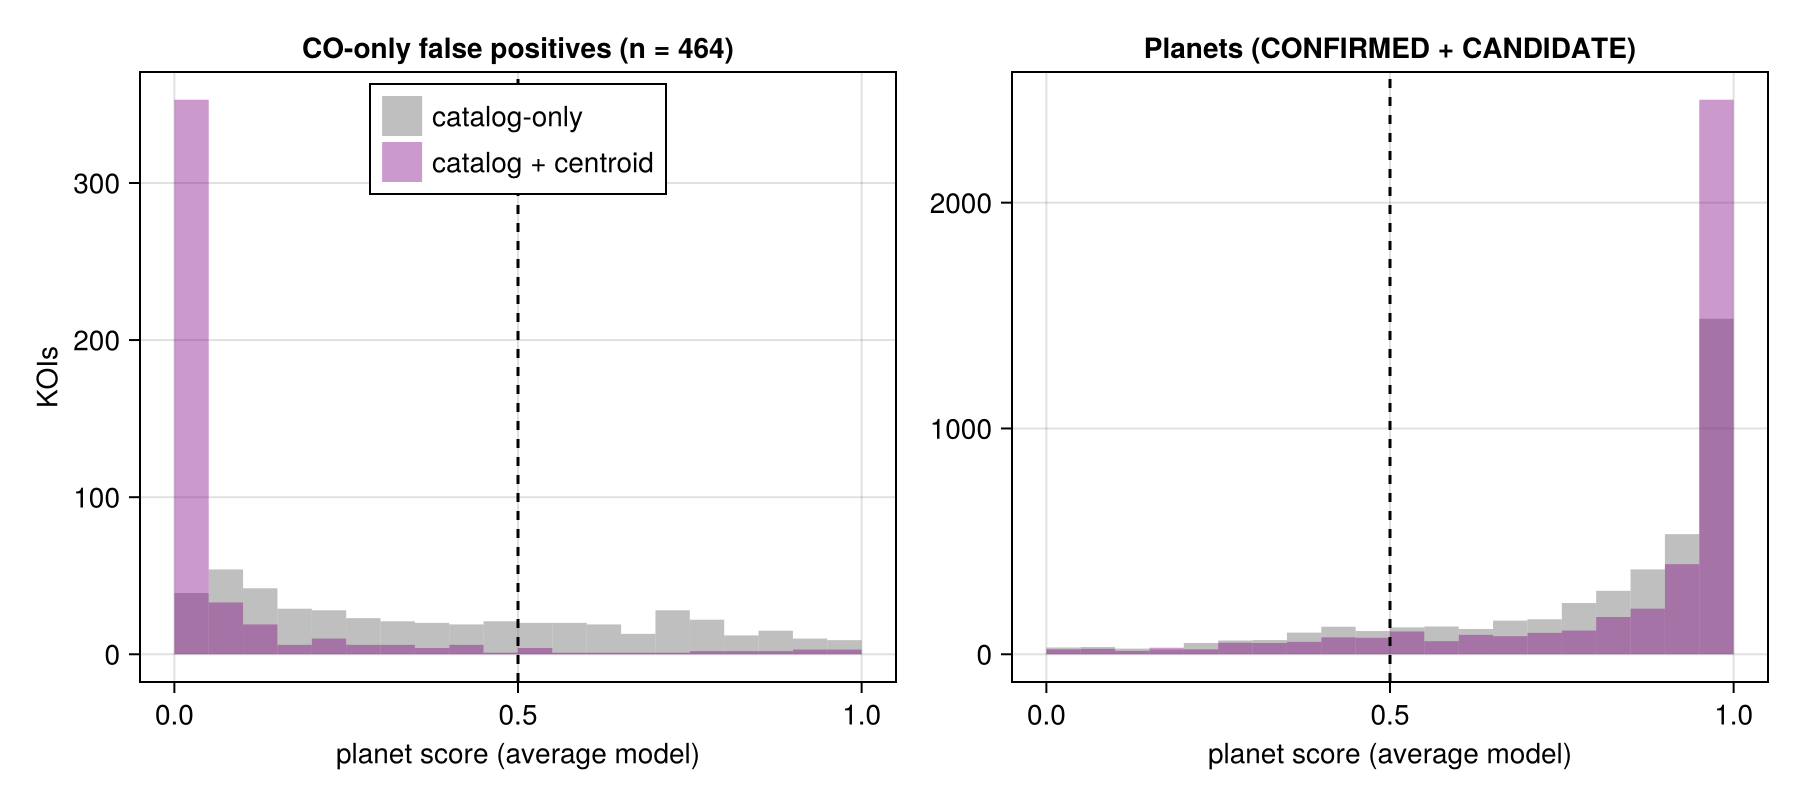

In [25]:
fig = Figure(size = (900, 400))
for (j, (t, m)) in enumerate((("CO-only false positives (n = $(sum(fp .& (a.flag_pattern .== "CO"))))", fp .& (a.flag_pattern .== "CO")),
                               ("Planets (CONFIRMED + CANDIDATE)", y .== 1)))
    local ax = Axis(fig[1, j]; xlabel = "planet score (average model)", ylabel = j == 1 ? "KOIs" : "", title = t)
    hist!(ax, s_av[m]; bins = 0:0.05:1, color = (:gray, 0.5), label = "catalog-only")
    hist!(ax, s_c[m]; bins = 0:0.05:1, color = (:purple, 0.4), label = "catalog + centroid")
    vlines!(ax, [0.5]; color = :black, linestyle = :dash)
    j == 1 && axislegend(ax; position = :ct)
end
savefig("exo101326_centroid_scores.png", fig)
fig

### 10.2 Supplemental KOIs: train on all KOIs, or on DR25 KOIs only?
Scored on DR25 KOIs (the headline set) and on supplemental KOIs. Δ = (DR25-only training) − (training on all).

In [26]:
scope_rows = NamedTuple[]
for (mname, A, B) in (("MLP + quantile", mq_d, mq), ("Trees, tuned", tr_d, tuned), ("MLP + trees average", avg_d, avg4))
    for (sname, m) in subsets[2:3]
        c = cmp_on(A, B, m)
        push!(scope_rows, (model = mname, scored_on = sname, train_all = c.B, train_dr25_only = c.A,
                           delta = @sprintf("%+.4f [%+.4f, %+.4f]", c.delta, c.ci_lo, c.ci_hi)))
    end
end
DataFrame(scope_rows)

Row,model,scored_on,train_all,train_dr25_only,delta
,String,String,Float64,Float64,String
1,MLP + quantile,DR25 KOIs (headline),0.953124,0.952919,"-0.0002 [-0.0010, +0.0006]"
2,MLP + quantile,supplemental KOIs,0.665538,0.635852,"-0.0297 [-0.0498, -0.0098]"
3,"Trees, tuned",DR25 KOIs (headline),0.952947,0.953618,"+0.0007 [-0.0001, +0.0015]"
4,"Trees, tuned",supplemental KOIs,0.659292,0.621012,"-0.0383 [-0.0575, -0.0190]"
5,MLP + trees average,DR25 KOIs (headline),0.955207,0.955459,"+0.0003 [-0.0005, +0.0009]"
6,MLP + trees average,supplemental KOIs,0.6678,0.629245,"-0.0386 [-0.0576, -0.0200]"


### 10.3 New headline table: DR25-detected KOIs
Every model scored on the 7,199 DR25 KOIs of the pool (supplemental KOIs reported alongside). The robovetter's
`koi_score` is shown for reference only: it is partly circular with the labels and uses pixel-level tests.

In [27]:
ks = coalesce.(a.koi_score, NaN)
headline_models = [("MLP baseline (exo100926)", base), ("MLP + quantile", mq), ("Trees, tuned", tuned),
                   ("MLP + trees average", avg4), ("Average, catalog + centroid", avg_c)]
hl = DataFrame(model = String[], dr25_roc_auc = Float64[], dr25_ci = String[], dr25_conf_vs_fp = Float64[], supplemental_roc_auc = Float64[])
for (name, cv) in headline_models
    s = oof_scores(cv)
    bs = star_bootstrap(y[dr], s[dr], pool.kepid[dr]; B = 1000)
    conf = dr .& (pool.koi_disposition .!= "CANDIDATE")
    push!(hl, (name, fast_auc(y[dr], s[dr]), @sprintf("[%.4f, %.4f]", bs.lo, bs.hi), fast_auc(y[conf], s[conf]),
               fast_auc(y[.!dr], s[.!dr])))
end
mk = dr .& isfinite.(ks)
push!(hl, ("robovetter koi_score (reference)", fast_auc(y[mk], ks[mk]), "—",
           fast_auc(y[mk .& (pool.koi_disposition .!= "CANDIDATE")], ks[mk .& (pool.koi_disposition .!= "CANDIDATE")]), NaN))
hl

Row,model,dr25_roc_auc,dr25_ci,dr25_conf_vs_fp,supplemental_roc_auc
,String,Float64,String,Float64,Float64
1,MLP baseline (exo100926),0.947545,"[0.9427, 0.9522]",0.969659,0.651867
2,MLP + quantile,0.953124,"[0.9487, 0.9577]",0.977054,0.665538
3,"Trees, tuned",0.952947,"[0.9486, 0.9573]",0.976311,0.659292
4,MLP + trees average,0.955207,"[0.9510, 0.9596]",0.978301,0.6678
5,"Average, catalog + centroid",0.982993,"[0.9806, 0.9853]",0.994515,0.75487
6,robovetter koi_score (reference),0.970255,—,0.983776,NaN


**Reading section 10:**
- **Centroid features are by far the biggest single gain so far.**
  - Average model on DR25 KOIs: 0.955 → **0.983** (Δ +0.028 [+0.024, +0.032]); all KOIs: 0.935 → 0.970.
  - Supplemental KOIs: 0.67 → 0.75.
  - **Not a missing-data artifact:** the gain is the same (+0.034) on KOIs that actually have centroid measurements.
- **The centroid-offset blind spot is essentially closed.**

  | Average model, threshold 0.5 | Catalog-only | + centroid |
  |---|---|---|
  | CO-only FPs missed | 36% | **4.3%** |
  | CO/EC FPs missed | 19% | 5% |
  | All FPs missed | 15% | 10% |
  | CONFIRMED called FP | 3.6% | 1.4% |
  | Planets with P < 1.5 d called FP | 58% | 32% |

  USP planets probably gain because clean centroids vouch for small, on-target signals.
  Not-transit-like and contamination FPs are not helped: NT 22% → 27%, EC 23% → 25%, partly a threshold shift.
- **⚠ Circularity: read 0.983 with care.**
  - The robovetter set the CO flag (and many FP dispositions) by thresholding these same centroid statistics.
  - Part of the gain is the model re-learning that rule, which is why it now even out-ranks the robovetter's own
    `koi_score` on DR25 KOIs (0.983 vs 0.970; koi_score was never built to maximise AUC).
  - **The catalog-only model (0.955 on DR25) remains the "independent" reference.** The centroid model is the
    "best use of available DV diagnostics" reference. Report both, always side by side.
- **Supplemental KOIs: keep training on everything.**
  - Training on DR25 KOIs only changes nothing for DR25 KOIs (Δ between −0.0002 and +0.0007, all CIs include 0).
  - It makes supplemental KOIs clearly worse (−0.03 to −0.04).
  - So the plan stands: train on all KOIs, headline on DR25 KOIs, report supplemental KOIs separately.
- **New headline numbers (DR25 KOIs, pooled OOF):**

  | Model | ROC-AUC |
  |---|---|
  | Original MLP | 0.948 |
  | Catalog-only MLP + trees | **0.955** [0.951, 0.960] |
  | Catalog + centroid | **0.983** [0.981, 0.985] |
  | Robovetter `koi_score` (reference) | 0.970 |

## 11. Step 5: calibration and operating points
**Questions:** are the two final models' scores honest probabilities, and which decision thresholds are on offer?
- **Models:** catalog-only (quantile MLP + tuned trees, 50/50 average) and catalog + centroid (the same, with the
  7 centroid features). Both always reported side by side.
- **Per-repeat scores.** The model we would ship is ONE 10-seed ensemble, so calibration uses each fold shuffle's
  seed-mean separately. (The repeat-mean used for AUC above is a 50-model ensemble: smoother than anything shipped.)
- **Calibrators compared:** none, Platt (logistic on logit score) and isotonic.
- **Nested, so the numbers are honest:** for each held-out fold, the calibrator and every threshold are fitted on
  the *other* folds' out-of-fold scores, then applied to the held-out fold.
- **Thresholds are picked on DR25 KOIs** (the headline set), with one threshold for every KOI: provenance is never
  used to set a KOI's threshold. Supplemental KOIs are reported separately at the same threshold.
- **User decisions (10/13):** report a menu of operating points rather than one; open the sealed test set later,
  together. The frozen models are made by `sweeps/step5_freeze.jl` (`models/step5_frozen.jld2`).

In [28]:
yf = Float64.(y)
conf = pool.koi_disposition .== "CONFIRMED"
final_models = [("catalog-only", (repeat_scores(mq) .+ repeat_scores(tuned)) ./ 2),
                ("catalog + centroid", (repeat_scores(mq_c) .+ repeat_scores(tr_c)) ./ 2)]
folds5 = base.folds
cal_subsets = [("DR25 KOIs", dr), ("supplemental KOIs", .!dr), ("all KOIs", trues(length(yf)))]
cal_rows = NamedTuple[]
for (mname, S) in final_models, meth in (:none, :platt, :isotonic)
    P = nested_calibrate(S, folds5, yf, meth)
    for (sname, m) in cal_subsets
        avg(f) = mean(f(yf[m], P[m, r]) for r in axes(P, 2))
        push!(cal_rows, (model = mname, calibrator = string(meth), subset = sname, logloss = round(avg(logloss); digits = 4),
                         brier = round(avg(brier); digits = 4), ece = round(avg(ece); digits = 4),
                         roc_auc = round(avg(fast_auc); digits = 4), mean_p = round(mean(P[m, :]); digits = 3),
                         planet_rate = round(mean(yf[m]); digits = 3)))
    end
end
for (mname, S) in final_models
    c = fit_platt(vec(S), repeat(yf, size(S, 2)))
    @printf("%s: Platt fit on all OOF scores: a = %.3f, b = %+.3f  (a = 1, b = 0 means already calibrated)\n", mname, c.a, c.b)
end
DataFrame(cal_rows)

catalog-only: Platt fit on all OOF scores: a = 1.039, b = -0.016  (a = 1, b = 0 means already calibrated)
catalog + centroid: Platt fit on all OOF scores: a = 1.054, b = -0.025  (a = 1, b = 0 means already calibrated)


Row,model,calibrator,subset,logloss,brier,ece,roc_auc,mean_p,planet_rate
,String,String,String,Float64,Float64,Float64,Float64,Float64,Float64
1,catalog-only,none,DR25 KOIs,0.2753,0.0839,0.0177,0.9542,0.512,0.513
2,catalog-only,none,supplemental KOIs,0.668,0.2311,0.0832,0.6639,0.447,0.431
3,catalog-only,none,all KOIs,0.3269,0.1032,0.0118,0.9339,0.504,0.502
4,catalog-only,platt,DR25 KOIs,0.2749,0.0838,0.0142,0.9541,0.511,0.513
5,catalog-only,platt,supplemental KOIs,0.6723,0.2321,0.0871,0.6633,0.442,0.431
6,catalog-only,platt,all KOIs,0.3271,0.1033,0.0094,0.9337,0.502,0.502
7,catalog-only,isotonic,DR25 KOIs,0.2768,0.0839,0.0119,0.9534,0.512,0.513
8,catalog-only,isotonic,supplemental KOIs,0.6858,0.233,0.0832,0.6595,0.435,0.431
9,catalog-only,isotonic,all KOIs,0.3305,0.1035,0.006,0.9328,0.502,0.502


Reliability per subset (uncalibrated, 15 equal-count bins, pooled over the 5 fold shuffles):

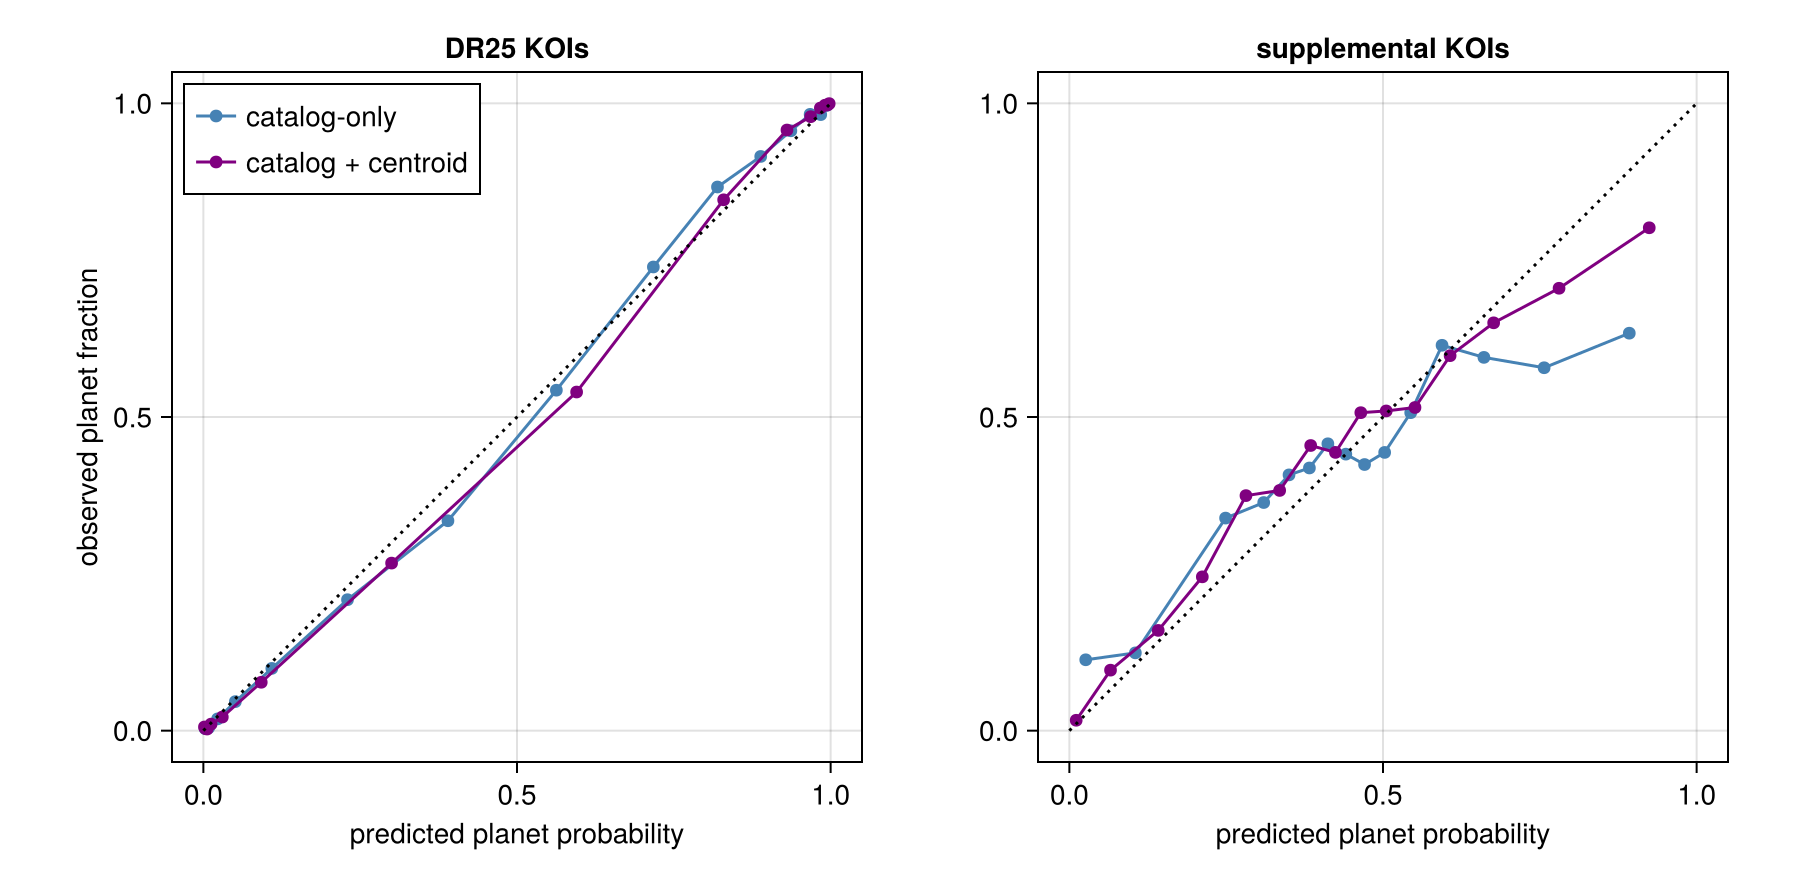

In [29]:
fig = Figure(size = (900, 440))
for (j, (sname, m)) in enumerate(cal_subsets[1:2])
    local ax = Axis(fig[1, j]; xlabel = "predicted planet probability", ylabel = j == 1 ? "observed planet fraction" : "",
                    title = sname, aspect = 1)
    for ((mname, S), col) in zip(final_models, (:steelblue, :purple))
        s, t = vec(S[m, :]), repeat(yf[m], size(S, 2))
        o = sortperm(s); e = round.(Int, range(0, length(s); length = 16))
        scatterlines!(ax, [mean(s[o[e[i]+1:e[i+1]]]) for i in 1:15], [mean(t[o[e[i]+1:e[i+1]]]) for i in 1:15];
                      color = col, label = mname)
    end
    lines!(ax, [0, 1], [0, 1]; color = :black, linestyle = :dot)
    j == 1 && axislegend(ax; position = :lt)
end
savefig("exo101326_step5_reliability.png", fig)
fig

### 11.1 Operating-point menu
Each rule picks a threshold (call "planet" if score ≥ t). Rates are nested estimates (threshold chosen without the
held-out fold), averaged over the 5 fold shuffles. *Frozen t* is the threshold stored with the final model (median
over fold shuffles, chosen on all pool DR25 KOIs). Per-1000 columns: out of 1,000 DR25 KOIs with this pool's mix
(51% planets).

In [30]:
RULES5 = [("planet recall 95%", (:recall, 0.95)), ("planet recall 98%", (:recall, 0.98)),
          ("planet recall 99%", (:recall, 0.99)), ("precision 95%", (:precision, 0.95)),
          ("precision 99%", (:precision, 0.99)), ("max F1", (:maxf1,)), ("p = 0.5", (:prob, 0.5))]
frozen = JLD2.load(joinpath(@__DIR__, "models", "step5_frozen.jld2"))["frozen"]
menu = NamedTuple[]
for ((mname, S), key) in zip(final_models, ("catalog_only", "catalog_centroid"))
    for (rname, rule) in RULES5
        nc = nested_calls(S, folds5, yf, dr, rule)
        rate(m, f) = mean(f(op_metrics(yf[m], Float64.(nc.calls[m, r]), 0.5)) for r in axes(S, 2))
        n_dr = sum(dr)
        push!(menu, (model = mname, rule = rname, frozen_t = round(frozen[key]["thresholds"][string(rule)]; digits = 3),
                     t_spread = round(std(nc.t); digits = 3),
                     dr25_recall = round(rate(dr, o -> o.recall); digits = 3),
                     dr25_precision = round(rate(dr, o -> o.precision); digits = 3),
                     dr25_fp_kept = round(rate(dr, o -> o.fp_kept); digits = 3),
                     planets_lost_per1000 = round(Int, 1000 * rate(dr, o -> o.fn) / n_dr),
                     fps_kept_per1000 = round(Int, 1000 * rate(dr, o -> o.fp) / n_dr),
                     confirmed_lost = round(rate(dr .& (conf .| (yf .== 0)), o -> 1 - o.recall); digits = 3),
                     supp_recall = round(rate(.!dr, o -> o.recall); digits = 3),
                     supp_precision = round(rate(.!dr, o -> o.precision); digits = 3)))
    end
end
menu_df = DataFrame(menu)
CSV.write(joinpath(CV_DIR, "step5_operating_points.csv"), menu_df)
menu_df

┌ Warning: type Main.TreeVetter does not exist in workspace; interpreting Array{Main.TreeVetter} as Array{Any}
└ @ JLD2 C:\JuliaDEPOT\packages\JLD2\rm5a0\src\datasets.jl:128
┌ Warning: type Main.TreeVetter does not exist in workspace; reconstructing
└ @ JLD2 C:\JuliaDEPOT\packages\JLD2\rm5a0\src\data\reconstructing_datatypes.jl:588


Row,model,rule,frozen_t,t_spread,dr25_recall,dr25_precision,dr25_fp_kept,planets_lost_per1000,fps_kept_per1000,confirmed_lost,supp_recall,supp_precision
,String,String,Float64,Float64,Float64,Float64,Float64,Int64,Int64,Float64,Float64,Float64
1,catalog-only,planet recall 95%,0.309,0.012,0.95,0.814,0.229,25,111,0.015,0.884,0.495
2,catalog-only,planet recall 98%,0.145,0.01,0.98,0.745,0.353,10,172,0.004,0.972,0.474
3,catalog-only,planet recall 99%,0.075,0.008,0.99,0.696,0.456,5,222,0.002,0.98,0.463
4,catalog-only,precision 95%,0.777,0.009,0.741,0.949,0.042,133,20,0.134,0.128,0.629
5,catalog-only,precision 99%,0.976,0.013,0.289,0.987,0.004,365,2,0.593,0.013,0.646
6,catalog-only,max F1,0.491,0.029,0.904,0.874,0.137,49,67,0.036,0.525,0.559
7,catalog-only,p = 0.5,0.5,0.0,0.9,0.881,0.129,52,63,0.038,0.496,0.574
8,catalog + centroid,planet recall 95%,0.442,0.017,0.95,0.913,0.096,26,47,0.011,0.67,0.609
9,catalog + centroid,planet recall 98%,0.211,0.014,0.98,0.856,0.173,10,84,0.004,0.943,0.528


The trade-off curve on DR25 KOIs (nested-free view: pooled uncalibrated scores of all 5 fold shuffles), with the
menu's frozen thresholds marked:

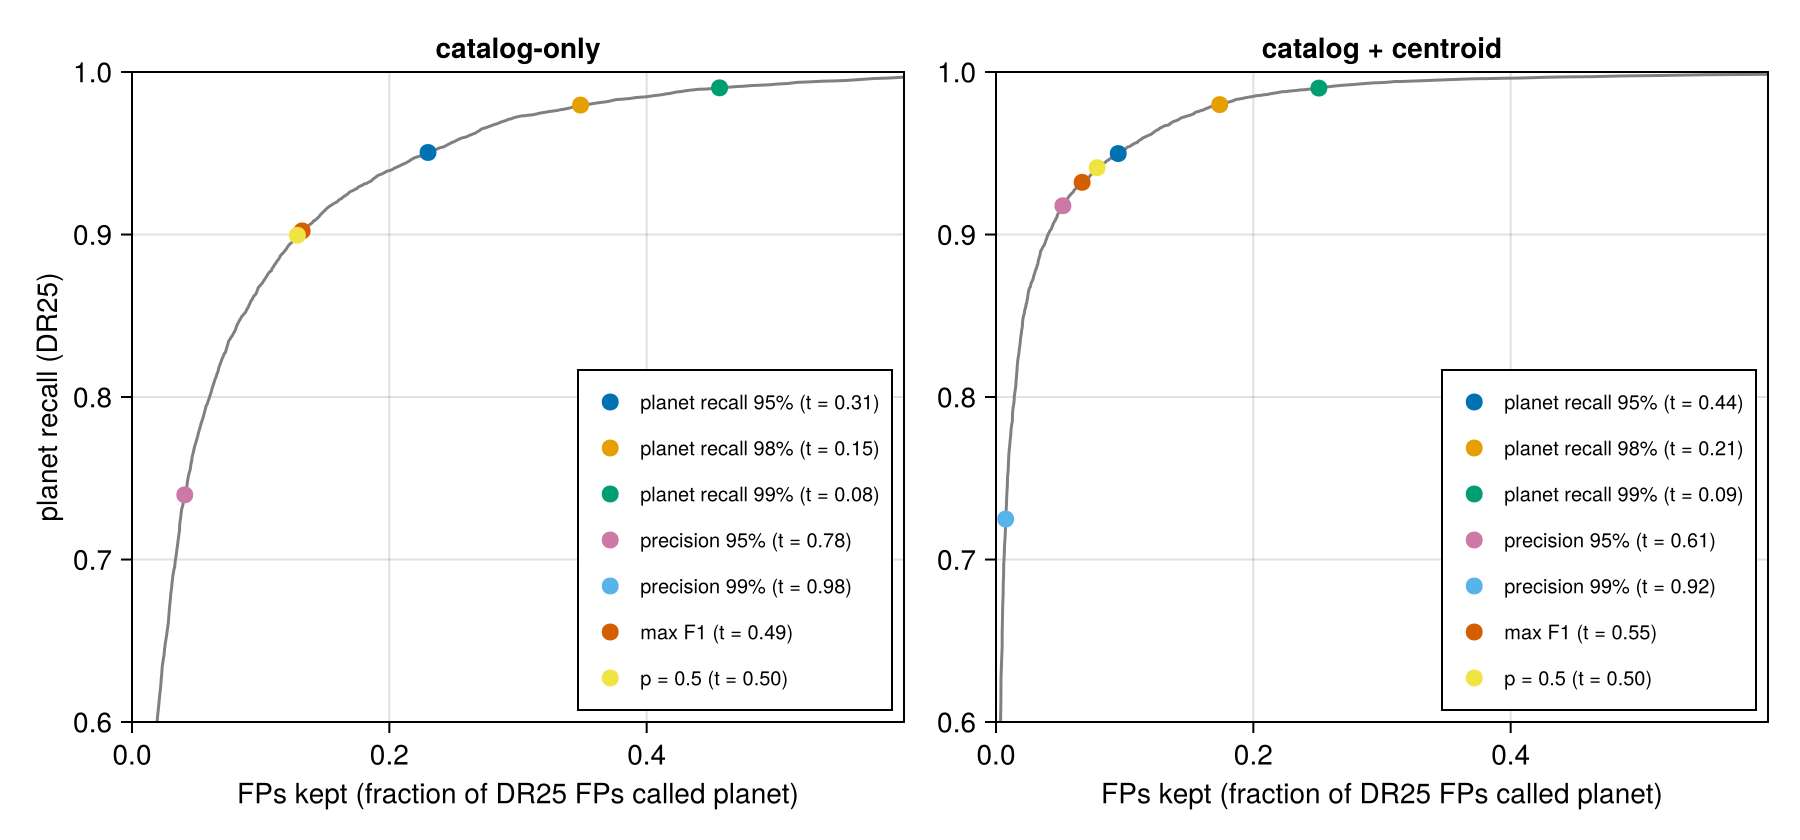

In [31]:
fig = Figure(size = (900, 420))
for (j, ((mname, S), key)) in enumerate(zip(final_models, ("catalog_only", "catalog_centroid")))
    local ax = Axis(fig[1, j]; xlabel = "FPs kept (fraction of DR25 FPs called planet)",
                    ylabel = j == 1 ? "planet recall (DR25)" : "", title = mname, limits = (0, 0.6, 0.6, 1.0))
    s, t = vec(S[dr, :]), repeat(yf[dr], size(S, 2))
    ts = range(0, 1; length = 401)
    lines!(ax, [mean(s[t .== 0] .>= u) for u in ts], [mean(s[t .== 1] .>= u) for u in ts]; color = :gray)
    for ((rname, rule), col) in zip(RULES5, Makie.wong_colors())
        u = frozen[key]["thresholds"][string(rule)]
        scatter!(ax, [mean(s[t .== 0] .>= u)], [mean(s[t .== 1] .>= u)]; color = col, markersize = 12,
                 label = @sprintf("%s (t = %.2f)", rname, u))
    end
    axislegend(ax; position = :rb, labelsize = 10)
end
savefig("exo101326_step5_menu.png", fig)
fig

**Reading section 11:**
- **Both models are already well calibrated; no calibrator is needed.**
  - A Platt fit on all OOF scores is almost the identity (a ≈ 1.04–1.05, b ≈ −0.02).
  - DR25 KOIs: ECE 0.018 (catalog-only) and 0.014 (centroid) uncalibrated. Platt and isotonic shave ECE by
    < 0.006 but don't improve log-loss or Brier (isotonic makes log-loss slightly *worse* and costs a little AUC
    through ties).
  - Frozen choice: **no calibrator**. The scores can be read as planet probabilities on DR25-like KOIs.
- **Supplemental KOIs are miscalibrated (ECE 0.05–0.08), and calibration can't fix it.**
  - The cause is weak ranking (AUC 0.66 / 0.75), not a shifted base rate (mean p 0.45 vs rate 0.43).
  - Fixing it would need a provenance-specific calibrator, i.e. using provenance as an input. Ruled out by decision.
  - So supplemental-KOI probabilities should be read as **unreliable**, and the menu reports them separately.
- **The thresholds are stable and the nested targets are hit** (DR25 recall 0.950 / 0.980 / 0.990 as asked;
  threshold spread across fold shuffles ≤ 0.04).
- **Centroid features buy a much better trade-off at every operating point**, for example at 98% planet recall:
  catalog-only keeps 35% of DR25 FPs, catalog + centroid 17%.
- **Nothing here touched the test split.** The frozen models + this menu are what the one-time test evaluation will
  score.

## 12. One-time sealed-test evaluation
- **The test split** (`split_by_star` seed 42, about 10% of stars) was scored exactly once by `sweeps/step5_test.jl`.
  It used the frozen models from section 11, with no fitting or tuning, and it refuses to run a second time.
- **Headline (user decision, 10/13):** ROC-AUC on DR25 KOIs, and the **98% planet recall** operating point. Best F1
  is shown alongside, and the full menu below.
- **"CV expected"** is the honest cross-validation estimate for the same quantity. For AUC, it's a single 10-seed
  ensemble per fold shuffle, averaged over shuffles. For operating points, it's the nested estimates from section 11.
- **The test set is small** (913 KOIs, 792 stars), so its confidence intervals (star bootstrap) are about 3× wider
  than the CV ones. The question is whether CV and test *agree*, not which is higher.

In [32]:
tp5 = CSV.read(joinpath(CV_DIR, "test_predictions.csv"), DataFrame)
yt, drt = Float64.(tp5.label), Bool.(tp5.dr25)
conft = tp5.koi_disposition .== "CONFIRMED"
@printf("test: %d KOIs, %d stars;  DR25 %d, supplemental %d;  planet rate %.3f\n",
        nrow(tp5), length(unique(tp5.kepid)), sum(drt), sum(.!drt), mean(yt))
test_models = [("catalog-only", tp5.p_catalog, final_models[1][2]), ("catalog + centroid", tp5.p_centroid, final_models[2][2])]
auc_rows = NamedTuple[]
for (mname, p, S) in test_models
    for (sname, mt, mc) in (("DR25 KOIs (headline)", drt, dr), ("DR25 CONFIRMED vs FP", drt .& (conft .| (yt .== 0)), dr .& (conf .| (yf .== 0))),
                            ("supplemental KOIs", .!drt, .!dr), ("all KOIs", trues(length(yt)), trues(length(yf))))
        bs = star_bootstrap(yt[mt], p[mt], tp5.kepid[mt]; B = 2000)
        cv_exp = mean(fast_auc(yf[mc], S[mc, r]) for r in axes(S, 2))
        push!(auc_rows, (model = mname, subset = sname, n = sum(mt), test_auc = round(fast_auc(yt[mt], p[mt]); digits = 4),
                         test_ci = @sprintf("[%.3f, %.3f]", bs.lo, bs.hi), cv_expected = round(cv_exp; digits = 4)))
    end
end
mk = drt .& isfinite.(tp5.koi_score)
push!(auc_rows, (model = "robovetter koi_score (reference)", subset = "DR25 KOIs (headline)", n = sum(mk),
                 test_auc = round(fast_auc(yt[mk], tp5.koi_score[mk]); digits = 4), test_ci = "—", cv_expected = NaN))
test_auc = DataFrame(auc_rows)
CSV.write(joinpath(CV_DIR, "test_auc.csv"), test_auc)
test_auc

test: 913 KOIs, 792 stars;  DR25 796, supplemental 117;  planet rate 0.499


Row,model,subset,n,test_auc,test_ci,cv_expected
,String,String,Int64,Float64,String,Float64
1,catalog-only,DR25 KOIs (headline),796,0.9573,"[0.944, 0.970]",0.9542
2,catalog-only,DR25 CONFIRMED vs FP,661,0.9745,"[0.964, 0.983]",0.9776
3,catalog-only,supplemental KOIs,117,0.7242,"[0.634, 0.812]",0.6639
4,catalog-only,all KOIs,913,0.9413,"[0.927, 0.956]",0.9339
5,catalog + centroid,DR25 KOIs (headline),796,0.9883,"[0.982, 0.994]",0.9825
6,catalog + centroid,DR25 CONFIRMED vs FP,661,0.9954,"[0.991, 0.999]",0.9942
7,catalog + centroid,supplemental KOIs,117,0.7875,"[0.704, 0.864]",0.751
8,catalog + centroid,all KOIs,913,0.9786,"[0.971, 0.986]",0.9692
9,robovetter koi_score (reference),DR25 KOIs (headline),796,0.9794,—,NaN


### 12.1 Operating points on the test set (frozen thresholds)

In [33]:
cvmenu = CSV.read(joinpath(CV_DIR, "step5_operating_points.csv"), DataFrame)
op_rows = NamedTuple[]
for ((mname, p, _), key) in zip(test_models, ("catalog_only", "catalog_centroid")), (rname, rule) in RULES5
    t = frozen[key]["thresholds"][string(rule)]
    o = op_metrics(yt[drt], p[drt], t)
    rec_bs = star_bootstrap(yt[drt], p[drt], tp5.kepid[drt]; B = 1000, metric = (a, b) -> op_metrics(a, b, t).recall)
    prec_bs = star_bootstrap(yt[drt], p[drt], tp5.kepid[drt]; B = 1000, metric = (a, b) -> op_metrics(a, b, t).precision)
    cvr = cvmenu[(cvmenu.model .== mname) .& (cvmenu.rule .== rname), :]
    oc = op_metrics(yt[drt .& (conft .| (yt .== 0))], p[drt .& (conft .| (yt .== 0))], t)
    os = op_metrics(yt[.!drt], p[.!drt], t)
    push!(op_rows, (model = mname, rule = rname, t = round(t; digits = 3),
                    recall = @sprintf("%.3f [%.3f, %.3f]", o.recall, rec_bs.lo, rec_bs.hi), cv_recall = cvr.dr25_recall[1],
                    precision = @sprintf("%.3f [%.3f, %.3f]", o.precision, prec_bs.lo, prec_bs.hi), cv_precision = cvr.dr25_precision[1],
                    fp_kept = round(o.fp_kept; digits = 3), cv_fp_kept = cvr.dr25_fp_kept[1],
                    confirmed_lost = round(1 - oc.recall; digits = 3), cv_confirmed_lost = cvr.confirmed_lost[1],
                    supp_recall = round(os.recall; digits = 2), supp_precision = round(os.precision; digits = 2)))
end
test_ops = DataFrame(op_rows)
CSV.write(joinpath(CV_DIR, "test_operating_points.csv"), test_ops)
test_ops

Row,model,rule,t,recall,cv_recall,precision,cv_precision,fp_kept,cv_fp_kept,confirmed_lost,cv_confirmed_lost,supp_recall,supp_precision
,String,String,Float64,String,Float64,String,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,catalog-only,planet recall 95%,0.309,"0.951 [0.929, 0.970]",0.95,"0.832 [0.792, 0.866]",0.814,0.2,0.229,0.026,0.015,0.96,0.5
2,catalog-only,planet recall 98%,0.145,"0.988 [0.975, 0.997]",0.98,"0.771 [0.731, 0.809]",0.745,0.305,0.353,0.0,0.004,0.96,0.47
3,catalog-only,planet recall 99%,0.075,"0.995 [0.987, 1.000]",0.99,"0.715 [0.674, 0.754]",0.696,0.413,0.456,0.0,0.002,1.0,0.47
4,catalog-only,precision 95%,0.777,"0.724 [0.673, 0.773]",0.741,"0.948 [0.922, 0.972]",0.949,0.041,0.042,0.148,0.134,0.1,0.62
5,catalog-only,precision 99%,0.976,"0.251 [0.184, 0.312]",0.289,"0.981 [0.955, 1.000]",0.987,0.005,0.004,0.649,0.593,0.0,0.0
6,catalog-only,max F1,0.491,"0.899 [0.868, 0.929]",0.904,"0.892 [0.861, 0.923]",0.874,0.113,0.137,0.055,0.036,0.5,0.58
7,catalog-only,p = 0.5,0.5,"0.894 [0.862, 0.924]",0.9,"0.894 [0.861, 0.924]",0.881,0.11,0.129,0.055,0.038,0.48,0.57
8,catalog + centroid,planet recall 95%,0.442,"0.973 [0.956, 0.987]",0.95,"0.934 [0.907, 0.956]",0.913,0.072,0.096,0.0,0.011,0.68,0.65
9,catalog + centroid,planet recall 98%,0.211,"0.993 [0.983, 1.000]",0.98,"0.869 [0.837, 0.898]",0.856,0.156,0.173,0.0,0.004,0.98,0.54


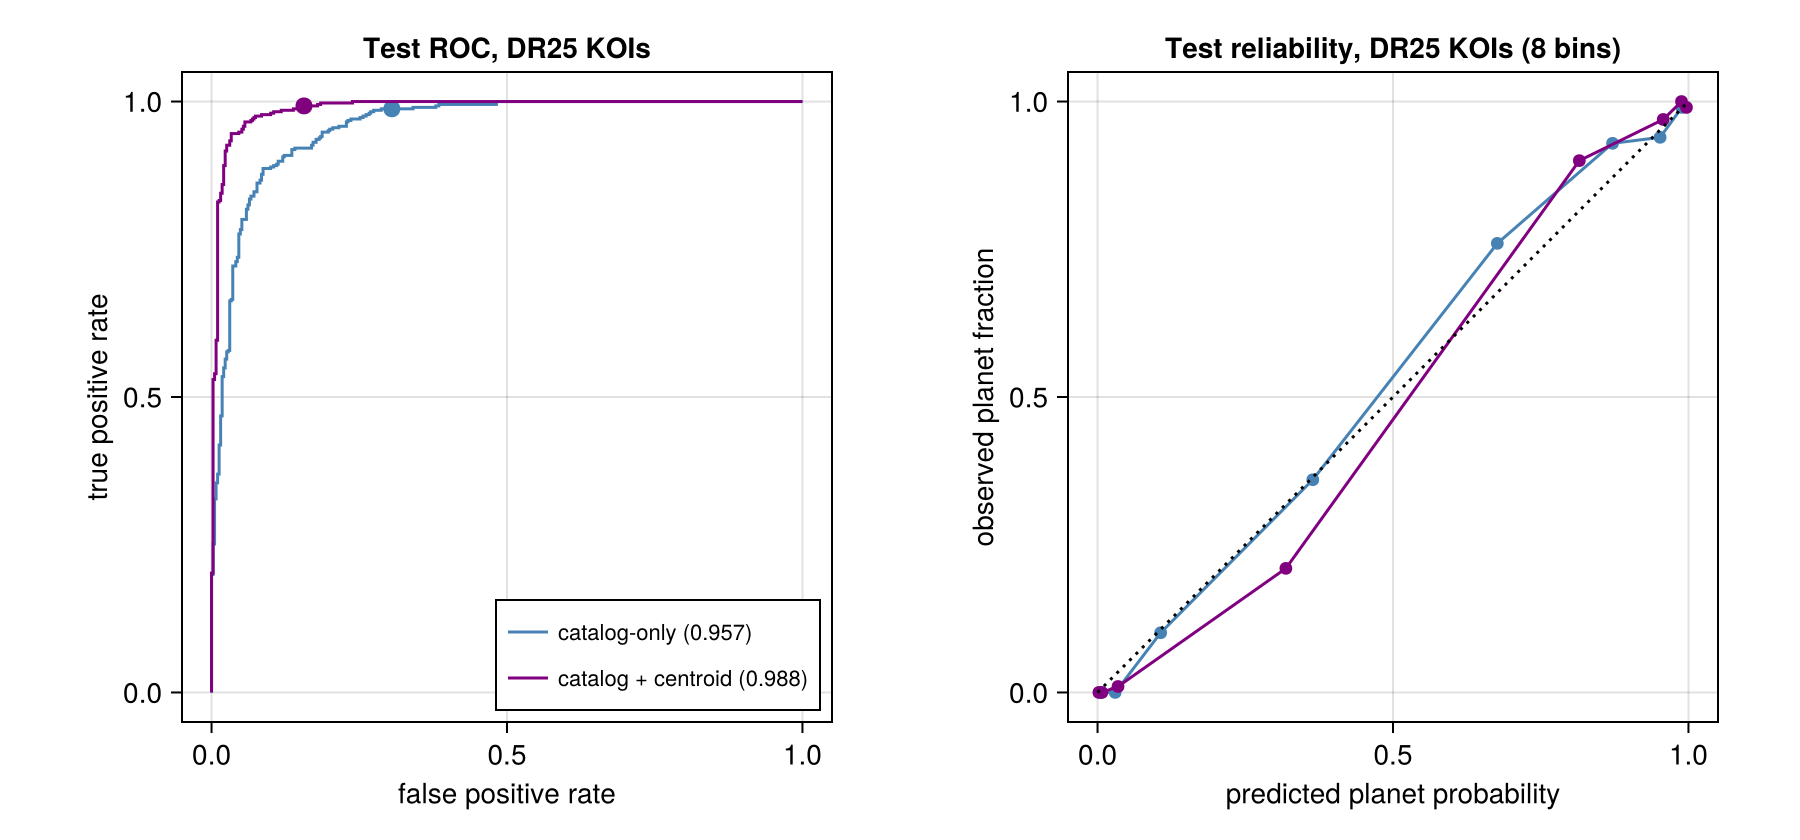

In [34]:
fig = Figure(size = (900, 420))
a1 = Axis(fig[1, 1]; xlabel = "false positive rate", ylabel = "true positive rate", title = "Test ROC, DR25 KOIs", aspect = 1)
a2 = Axis(fig[1, 2]; xlabel = "predicted planet probability", ylabel = "observed planet fraction",
          title = "Test reliability, DR25 KOIs (8 bins)", aspect = 1)
for ((mname, p, _), col) in zip(test_models, (:steelblue, :purple))
    fpr, tpr = roccurve(Int.(yt[drt]), p[drt])
    lines!(a1, fpr, tpr; color = col, label = @sprintf("%s (%.3f)", mname, fast_auc(yt[drt], p[drt])))
    t98 = frozen[mname == "catalog-only" ? "catalog_only" : "catalog_centroid"]["thresholds"]["(:recall, 0.98)"]
    o = op_metrics(yt[drt], p[drt], t98)
    scatter!(a1, [o.fp_kept], [o.recall]; color = col, markersize = 12)
    s, tt = p[drt], yt[drt]; ord = sortperm(s); e = round.(Int, range(0, length(s); length = 9))
    scatterlines!(a2, [mean(s[ord[e[i]+1:e[i+1]]]) for i in 1:8], [mean(tt[ord[e[i]+1:e[i+1]]]) for i in 1:8]; color = col)
end
lines!(a2, [0, 1], [0, 1]; color = :black, linestyle = :dot)
axislegend(a1; position = :rb, labelsize = 11)
savefig("exo101326_test.png", fig)
fig

**Reading section 12: the test set confirms the cross-validation results.**
- **Headline, DR25 KOIs:**

  | Model | Test ROC-AUC [95% CI] | CV expected |
  |---|---|---|
  | Catalog-only | **0.957** [0.944, 0.970] | 0.954 |
  | Catalog + centroid | **0.988** [0.982, 0.994] | 0.983 |
  | Robovetter `koi_score` (reference) | 0.979 | — |

  Every CV estimate lies inside the test CI, for both models and every subset. The test split is slightly easier
  than the pool (all subsets score a little higher), which is within its sampling noise.
- **The 98% planet-recall operating point holds:**
  - Catalog-only (t = 0.145): recall 0.988 [0.975, 0.997], precision 0.77, keeps 31% of FPs (CV: 35%).
  - Catalog + centroid (t = 0.211): recall 0.993 [0.983, 1.000], precision 0.87, keeps 16% of FPs (CV: 17%).
  - No CONFIRMED planet in the DR25 test KOIs is lost at this threshold, by either model.
- **Best F1 (for comparison with the literature):** catalog-only recall 0.90 / precision 0.89; catalog + centroid
  0.96 / 0.95.
- **Supplemental KOIs (117):** 0.72 and 0.79, also in line with CV (wide CIs, as expected).
- **The numbers are final.** The test set has been used; any later model change has to be judged by CV again and
  reported as post-test.